# Trotter step convergence at low $\omega$

At $\omega = 0.1$ one period is $T = 2\pi/\omega \approx 63$, so sticking with $\tau \approx 0.05$ and 20 periods like the higher $\omega$ runs is ~25,000 steps per run, about 10x what $\omega = 1$ needs. Checking how big I can make $\tau$ before things change, and how the error grows with the number of periods.

Same run at a few steps per period $N$ (sp), $\tau = T/N$, everything compared to the smallest $\tau$. All OBC, $m = 400$. Bond dim maxes out at $2^{L/2}$ (64 for $L = 12$, 128 for $L = 14$), so besides the $10^{-9}$ SVD cutoff nothing gets truncated and any difference should be Trotter error.

| L | periods | g | parity | sp | reference |
|---|---|---|---|---|---|
| 12 | 4 | 0.2, 1.0 | even, odd | 160 to 2560 | sp2560 ($\tau \approx 0.025$) |
| 12 | 20 | 0.2, 1.0, 2.0 | even | 480 to 3840 | sp3840 ($\tau \approx 0.016$) |
| 14 | 4 | 0.2, 1.0, 2.0 | even | 480 to 3840 | sp3840 ($\tau \approx 0.016$) |

Production at $\omega = 0.1$ would be sp1256 ($\tau = 0.050$). Closest I tested is sp1280 ($\tau \approx 0.049$).

In [24]:
import os
import re
import glob
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.style.use("../majorana.mplstyle")

root  = "trotter_*"
tol   = 1e-2
chans = {"x": r"$\langle X(t)X(0)\rangle$", "y": r"$\langle Y(t)Y(0)\rangle$",
         "z": r"$\langle Z(t)Z(0)\rangle$", "e": r"$\langle H(t)\rangle/L$"}
job_re   = re.compile(r"g(-?[\d.]+)_site(\d+)_p(even|odd)_sp(\d+)")
batch_re = re.compile(r"L(\d+)_\w+?_m(\d+)")

In [25]:
def load(fname):
    with h5py.File(fname, "r") as f:
        L = f["L"][()]
        d = {c: f[f"re_autoc_{c}"][()] + 1j * f[f"im_autoc_{c}"][()] for c in "xyz"}
        d["e"], d["E0"] = f["energy_t"][()] / L, f["E0_dmrg"][()] / L
        d["t"], d["T"] = f["times"][()], 2 * np.pi / f["omega"][()]
    return d

In [26]:
def compare(rs, t_win):
    sps = sorted(rs, reverse=True)
    assert all(sps[0] % sp == 0 for sp in sps), f"every sp must divide the reference sp{sps[0]}"
    ref, T = rs[sps[0]], rs[sps[0]]["T"]
    tau_ref = T / sps[0]
    out = {}
    for sp in sps[1:]:
        d, tau = rs[sp], T / sp
        mask = d["t"] <= t_win
        run_err = {c: np.maximum.accumulate(np.abs(d[c] - ref[c][:: sps[0] // sp])) for c in chans}
        out[sp] = {"tau": tau, "t": d["t"], "run_err": run_err,
                   "eps": {c: run_err[c][mask][-1] * tau**2 / (tau**2 - tau_ref**2) for c in chans}}
    for fine, sp in zip(sps[1:], sps[2:]):
        out[sp]["order"] = {c: np.log(out[sp]["eps"][c] / out[fine]["eps"][c]) / np.log(fine / sp) for c in chans}
    return out

In [27]:
runs = {}
for fname in sorted(glob.glob(os.path.join(root, "*", "*", "output.h5"))):
    *_, folder, batch, job, _ = fname.split(os.sep)
    g, _, p, sp = job_re.search(job).groups()
    runs.setdefault((f"{folder}/{batch}", float(g), p), {})[int(sp)] = load(fname)

results = {k: compare(rs, np.inf) for k, rs in sorted(runs.items())}
early   = {k: compare(rs, rs[max(rs)]["T"]) for k, rs in sorted(runs.items())}
batches = sorted({k[0] for k in results})

def gs(b):
    return sorted({k[1] for k in results if k[0] == b})

def par(b, g):
    return "even" if (b, g, "even") in results else "odd"

def desc(b):
    rs = next(rs for k, rs in runs.items() if k[0] == b)
    d, L, m = rs[max(rs)], *batch_re.search(b).groups()
    return (rf"$L = {L}$, $m = {m}$, $\omega = {2 * np.pi / d['T']:.3g}$, ${d['t'][-1] / d['T']:.0f}$ periods, "
            rf"reference sp{max(rs)} ($\tau = {d['T'] / max(rs):.3f}$)")

def excess(rs):
    n = round(rs[max(rs)]["t"][-1] / rs[max(rs)]["T"])
    return {sp: d["e"][sp::sp][:n] - d["E0"] for sp, d in rs.items()}

def period_rms(a, n):
    return np.sqrt(np.mean(np.abs(a[:, 1:].reshape(3, n, -1)) ** 2, axis=(0, 2)))

def plot_eps(res_all, b, note=""):
    fig, ax = plt.subplots(1, len(gs(b)), figsize=(5 * len(gs(b)), 4), squeeze=False, dpi=150)
    for j, g in enumerate(gs(b)):
        for p, ls in [("even", "-"), ("odd", "--")]:
            if (b, g, p) not in res_all:
                continue
            res = res_all[(b, g, p)]
            taus = np.array([r["tau"] for r in res.values()])
            for k, c in enumerate(chans):
                ax[0, j].loglog(taus, [r["eps"][c] for r in res.values()], ls, marker="o", ms=3, color=f"C{k}", label=f"${c}$ {p}")
        e0 = np.median([res[max(res)]["eps"][c] for c in chans])
        ax[0, j].loglog(taus, e0 * (taus / taus.min()) ** 2, "k:", label=r"$\propto\tau^2$")
        ax[0, j].axhline(tol, color="gray", lw=0.8)
        ax[0, j].set_xticks(taus, [f"${t:.3f}$\nsp{sp}" for t, sp in zip(taus, res)])
        ax[0, j].xaxis.set_minor_formatter(plt.NullFormatter())
        ax[0, j].set(title=rf"$g = {g}$", xlabel=r"$\tau$", ylabel=r"$\varepsilon(\tau)$")
    ax[0, 0].legend(fontsize=6, handlelength=3.5)
    fig.suptitle(desc(b) + note, fontsize=10)
    fig.tight_layout()

## Comparison

Every sp divides the reference sp, so the time grids line up. Trotter is second order, $A_\tau \approx A + C\tau^2$, and the reference has its own error, so the error of the coarser run is
$$\varepsilon(\tau) = |C|\tau^2 = \max_t |A_\tau - A_\text{ref}|\,\frac{\tau^2}{\tau^2 - \tau_\text{ref}^2}$$
(factor is 9/8 for sp1280 vs sp3840). $p$ is the log-log slope of $\varepsilon$ between neighboring $\tau$, should be ~2.

This only holds while the error is small. Trotter shifts the frequencies by ~$\tau^2$, so the runs slowly drift out of phase. Once they've drifted enough, the difference is just the size of the signal no matter what $\tau$ is. Then $\varepsilon$ goes flat and $p$ doesn't mean much. The reference drifts too, just slower.

## Early times

Same $\varepsilon$ but only over the first period. Solid even, dashed odd, dotted $\tau^2$, gray $10^{-2}$.

- $g \le 1$ follows $\tau^2$ except at the biggest steps (sp320 and sp160 in the first batch).
- $g = 0.2$: a few curves level off at the smallest steps (~$10^{-3}$ for the autocorrelations). Maybe the SVD cutoff adding up over more steps?
- $g = 2.0$: only the finer steps follow $\tau^2$.
- $L = 12$ and 14 look about the same, so a $\tau$ picked at small $L$ should hopefully carry over to $L = 24$.

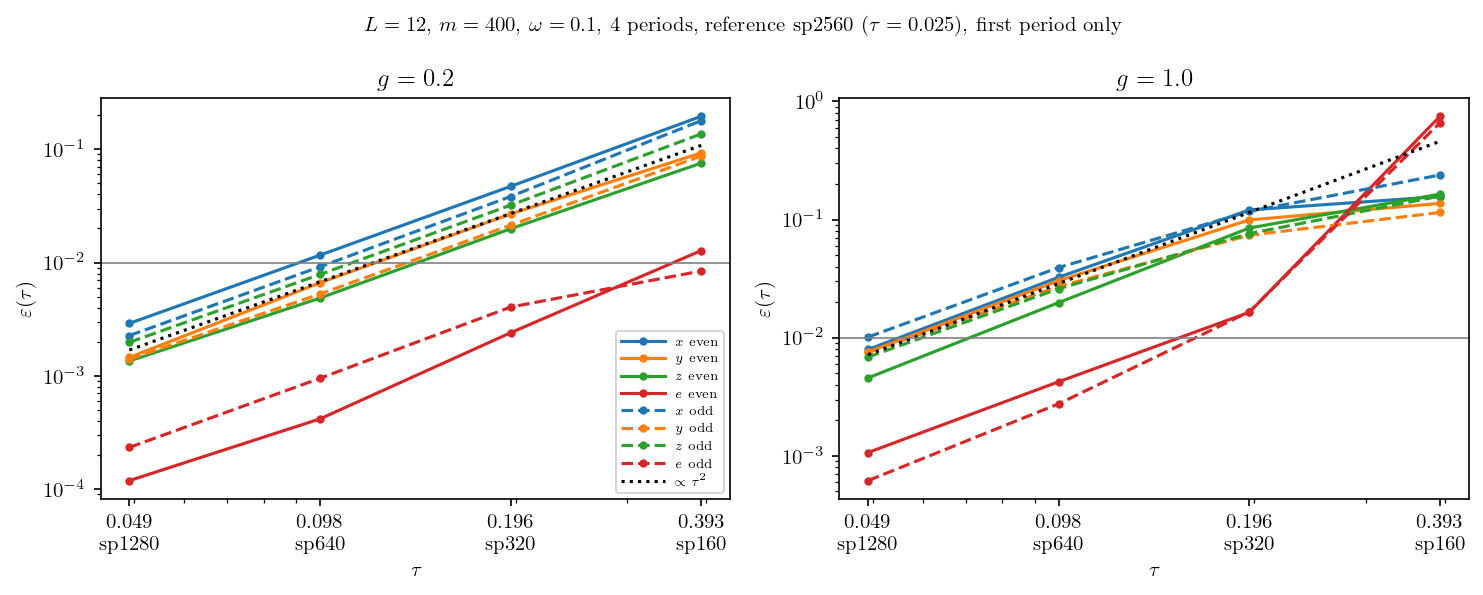

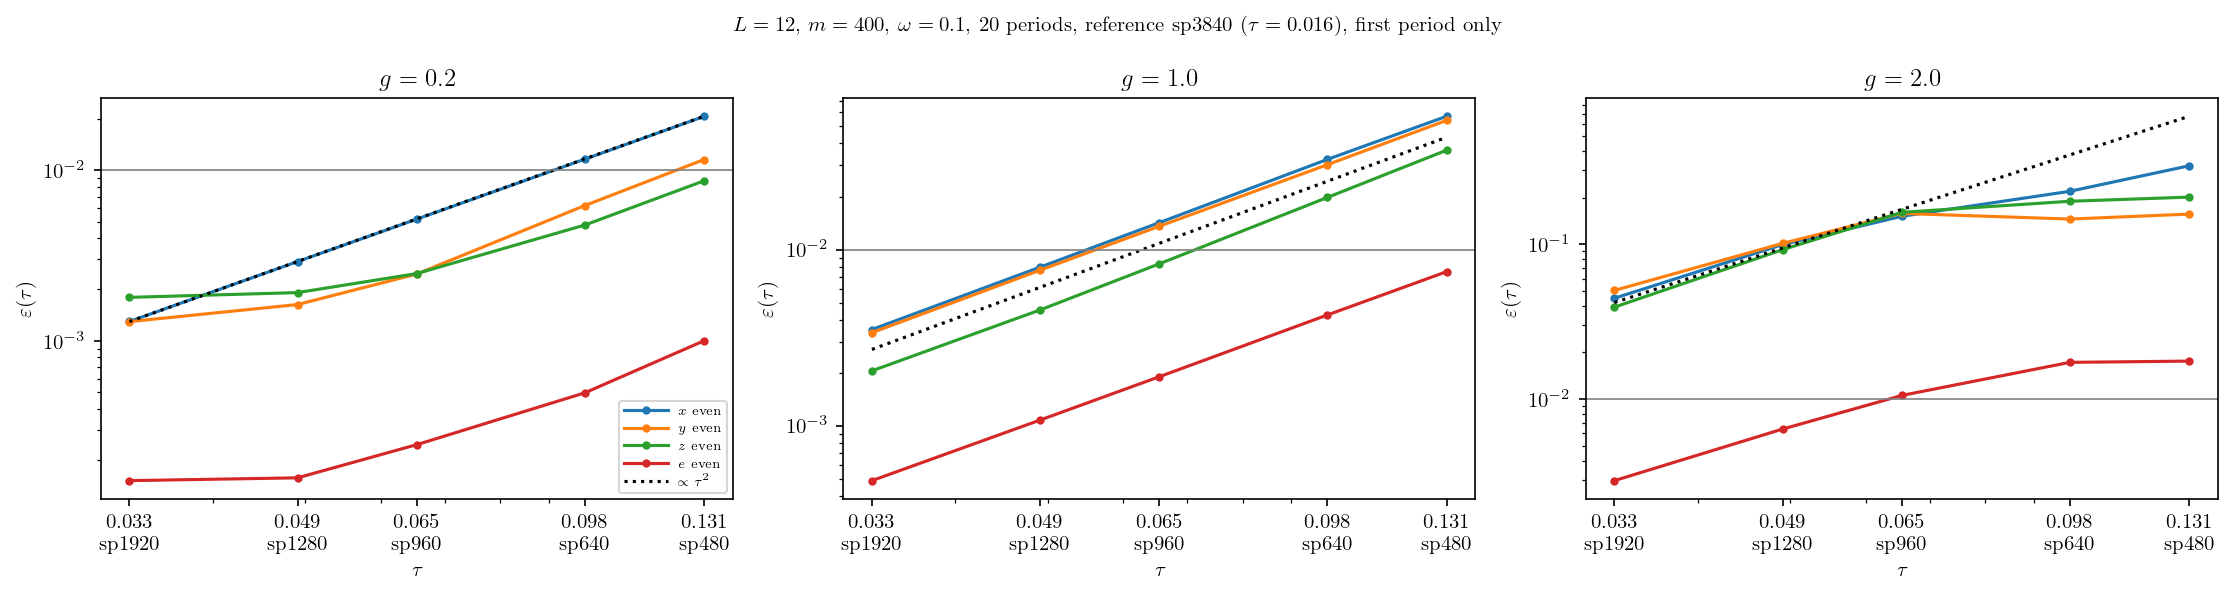

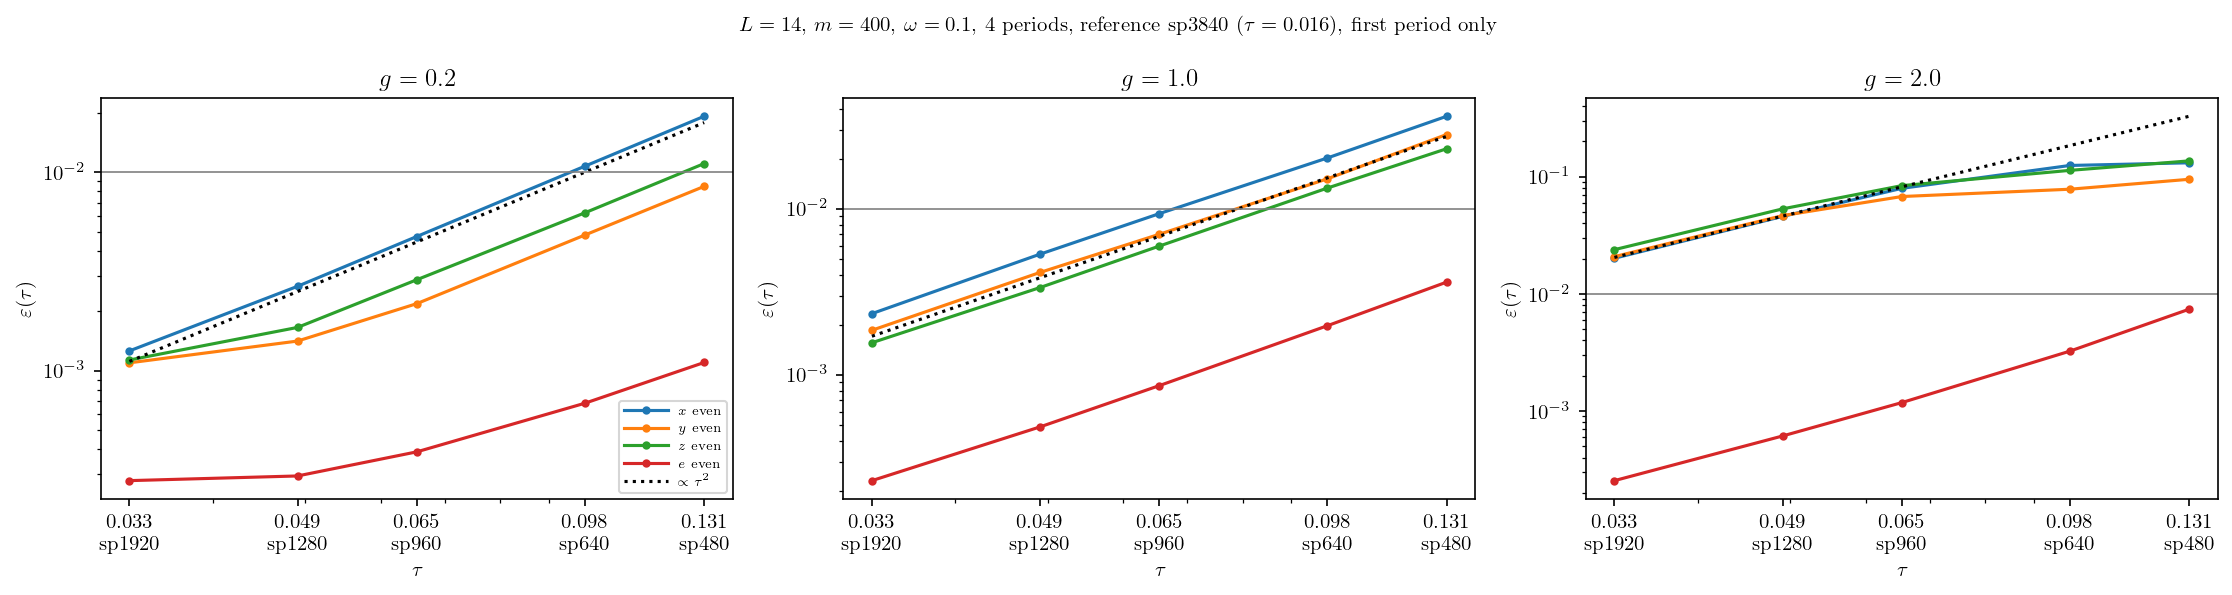

In [28]:
for b in batches:
    plot_eps(early, b, ", first period only")

## Excess energy at $t = nT$

$E_\text{exc}(t) = \langle H(t)\rangle - E_0(t)$, same as the production runs. At $t = nT$ the drive is back at $t_1 = 1$, so $H(nT) = H(0)$ and $E_0$ is just the DMRG energy from the start of the run. No lookup table needed. Top: $E_\text{exc}(nT)/L$ for each $\tau$. Bottom: relative error vs the reference, gray line at 1%.

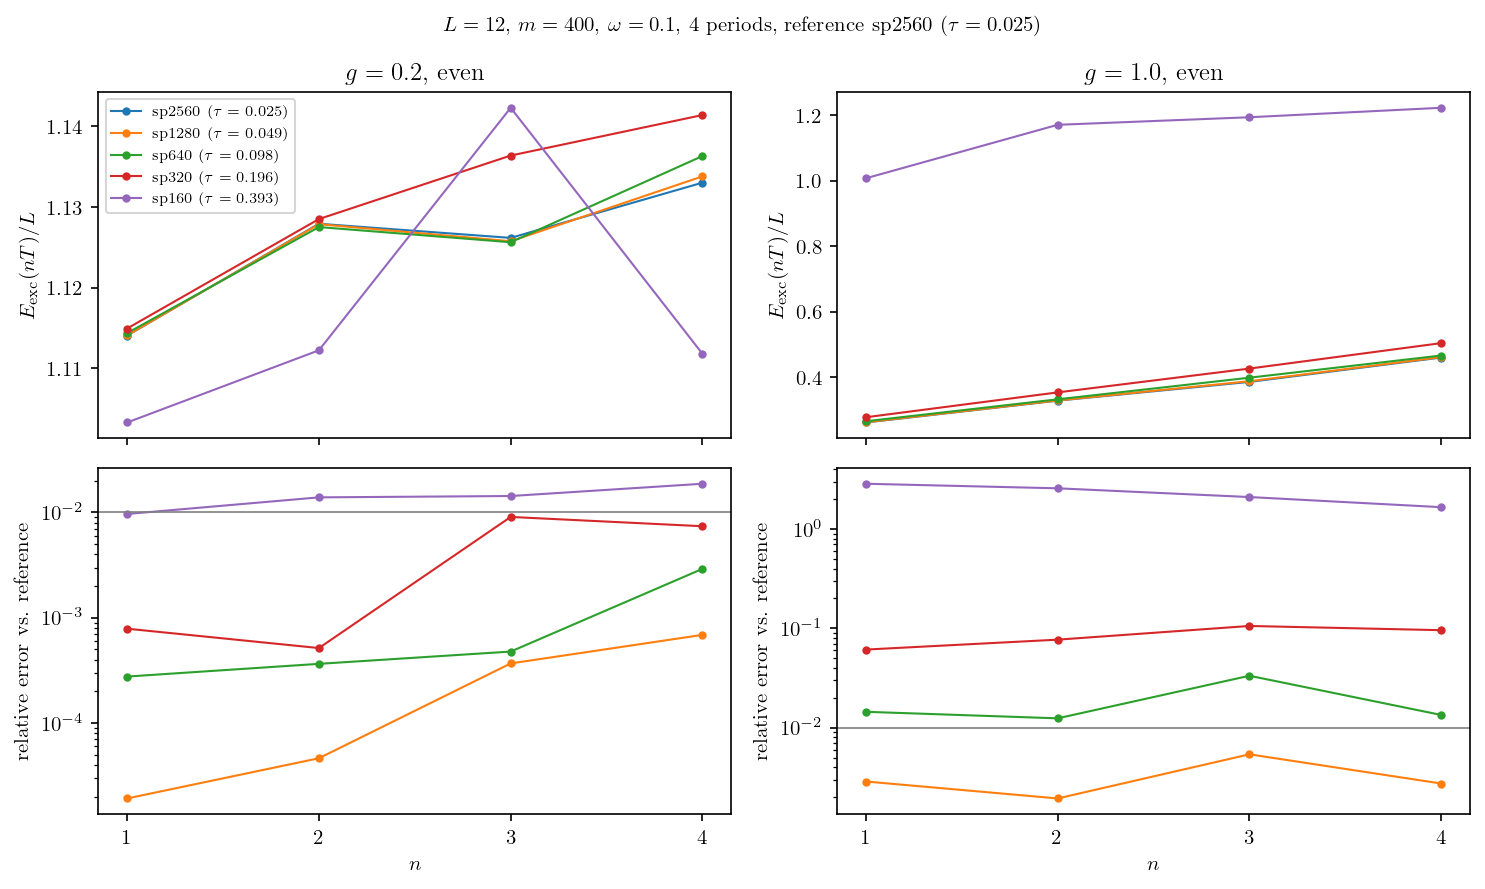

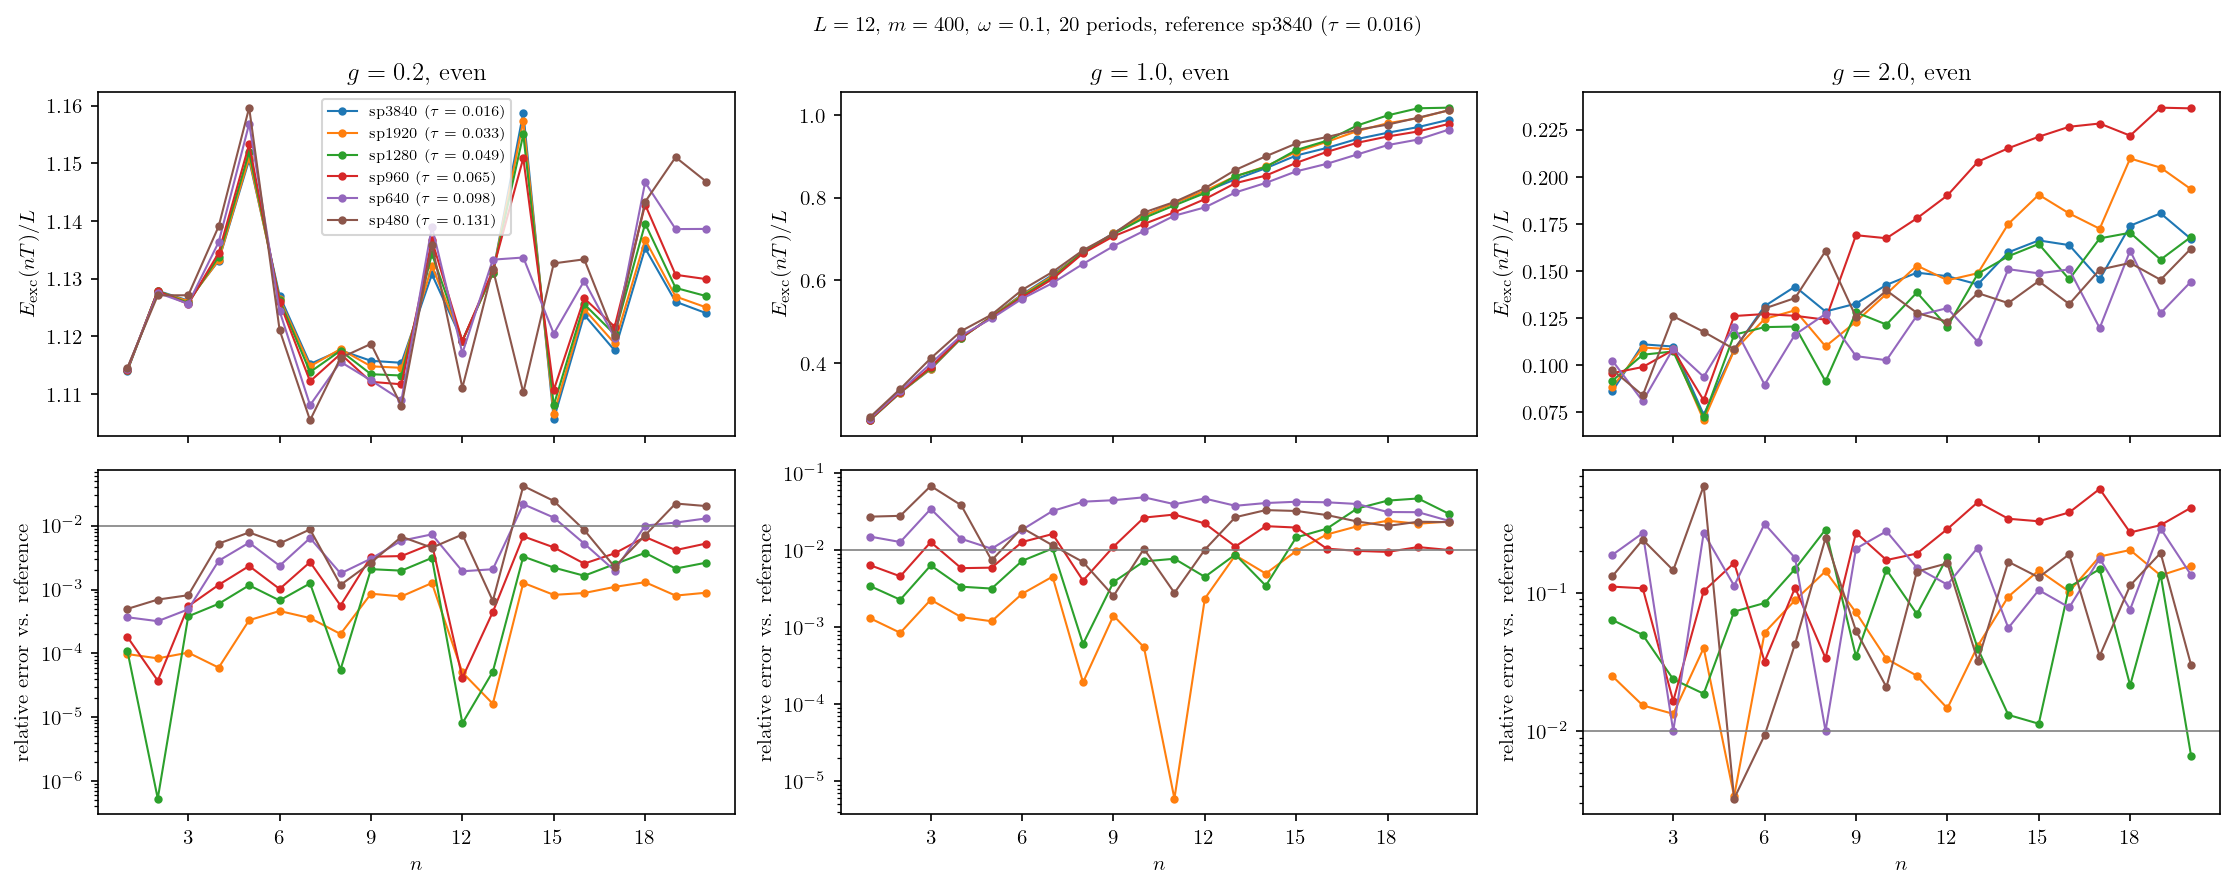

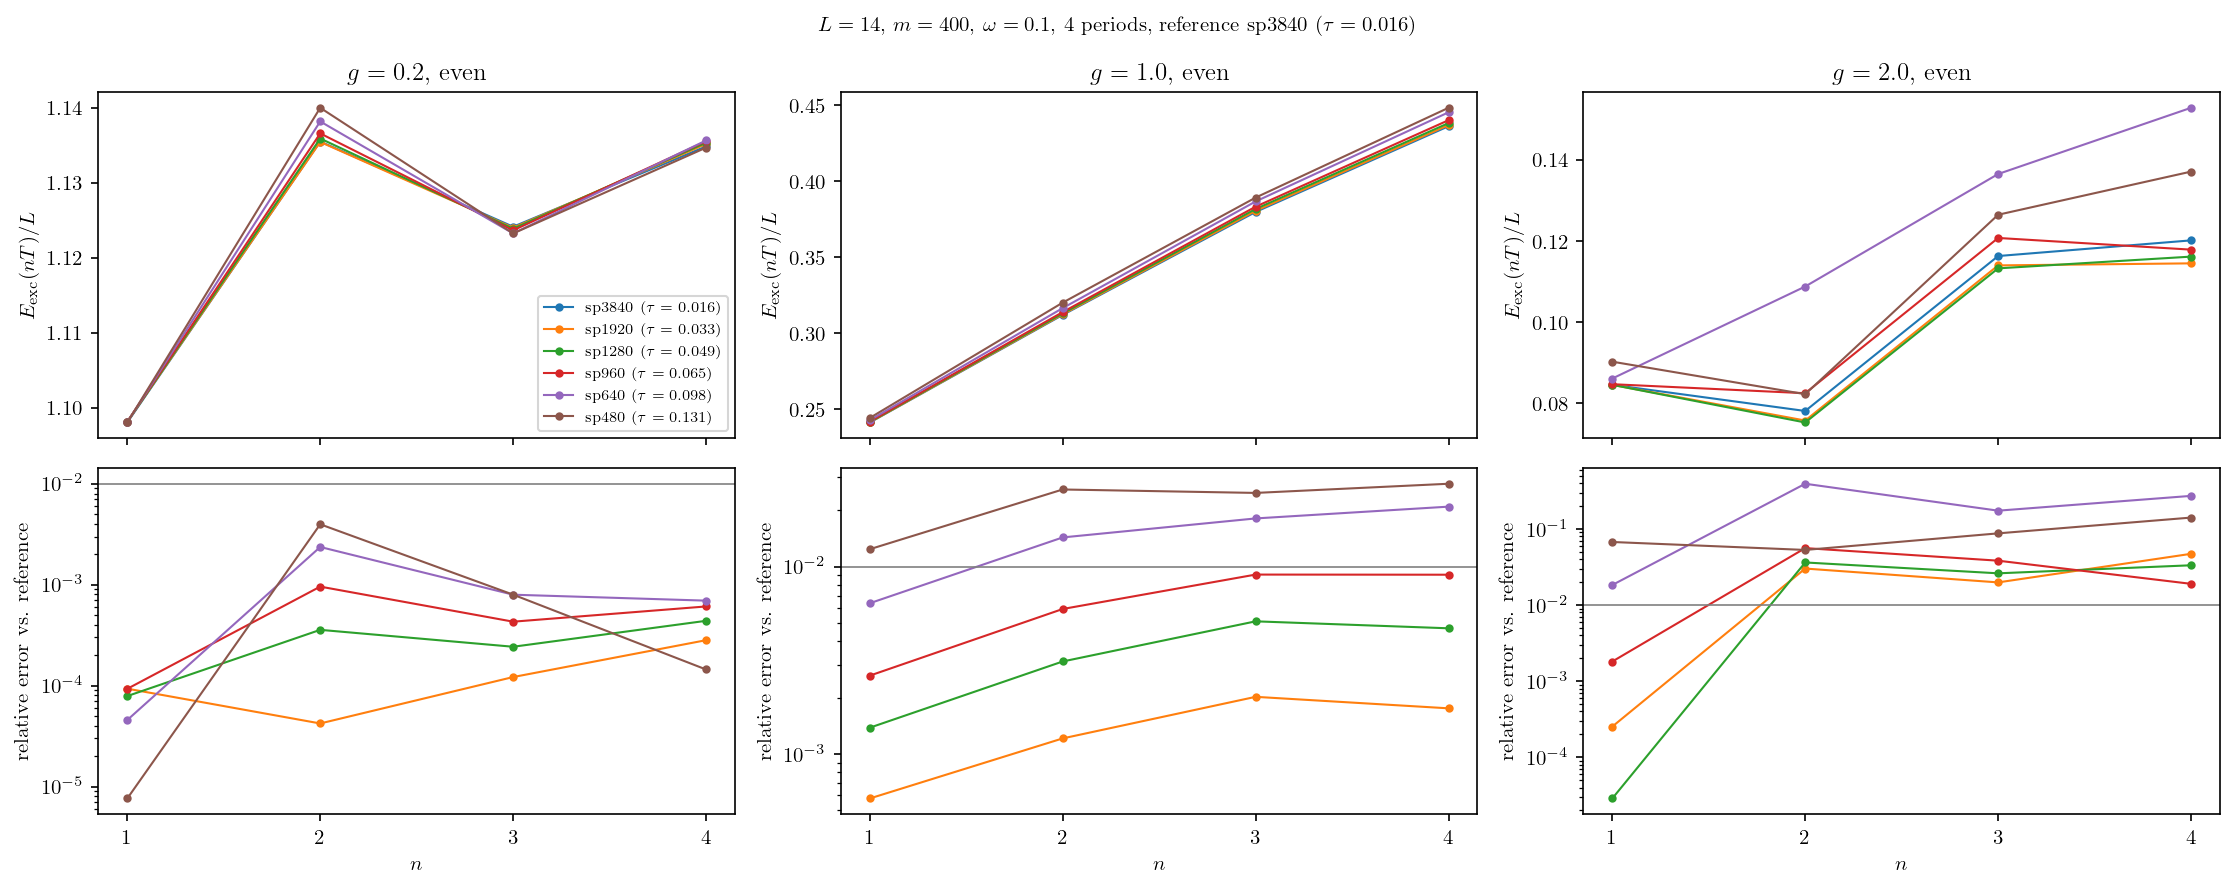

In [29]:
for b in batches:
    fig, ax = plt.subplots(2, len(gs(b)), figsize=(5 * len(gs(b)), 6), sharex=True, squeeze=False, dpi=150)
    for j, g in enumerate(gs(b)):
        rs = runs[(b, g, par(b, g))]
        Q = excess(rs)
        ref = max(Q)
        n = np.arange(1, len(Q[ref]) + 1)
        for i, sp in enumerate(sorted(Q, reverse=True)):
            ax[0, j].plot(n, Q[sp], marker="o", ms=3, lw=1, color=f"C{i}", label=rf"sp{sp} ($\tau = {rs[sp]['T'] / sp:.3f}$)")
            if sp != ref:
                ax[1, j].semilogy(n, np.abs(Q[sp] - Q[ref]) / Q[ref], marker="o", ms=3, lw=1, color=f"C{i}")
        ax[1, j].axhline(tol, color="gray", lw=0.8)
        ax[0, j].set(title=rf"$g = {g}$, {par(b, g)}", ylabel=r"$E_\mathrm{exc}(nT)/L$")
        ax[1, j].set(xlabel=r"$n$", ylabel="relative error vs. reference")
        ax[1, j].xaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0, 0].legend(fontsize=7)
    fig.suptitle(desc(b), fontsize=10)
    fig.tight_layout()

Worst relative error in $E_\text{exc}(nT)$ over the first $n$ periods. Red means over 1%.

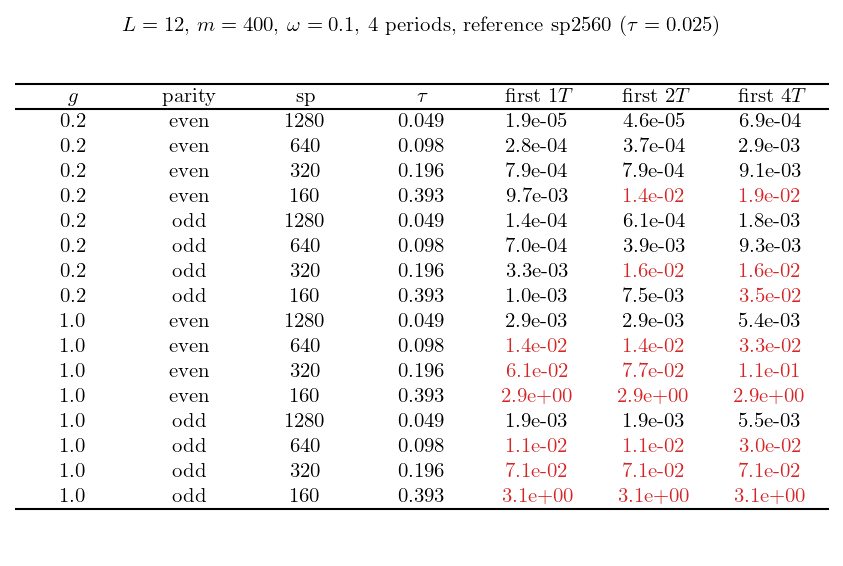

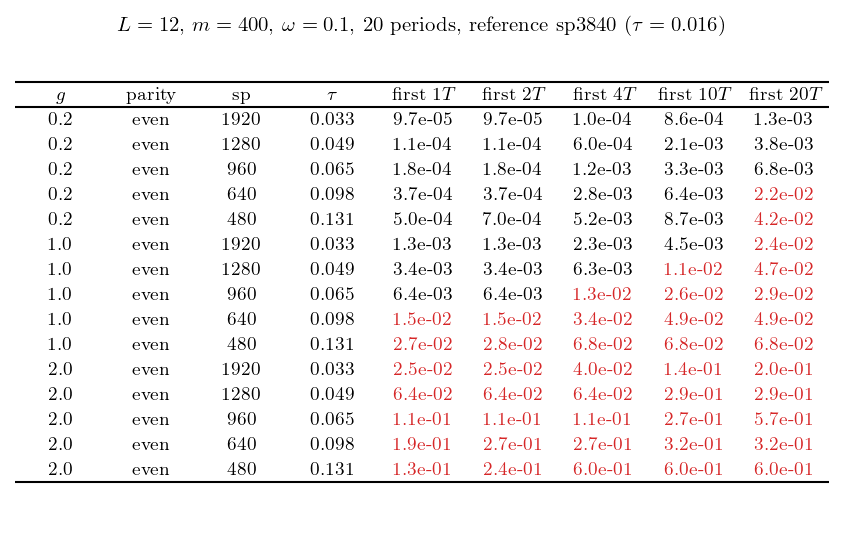

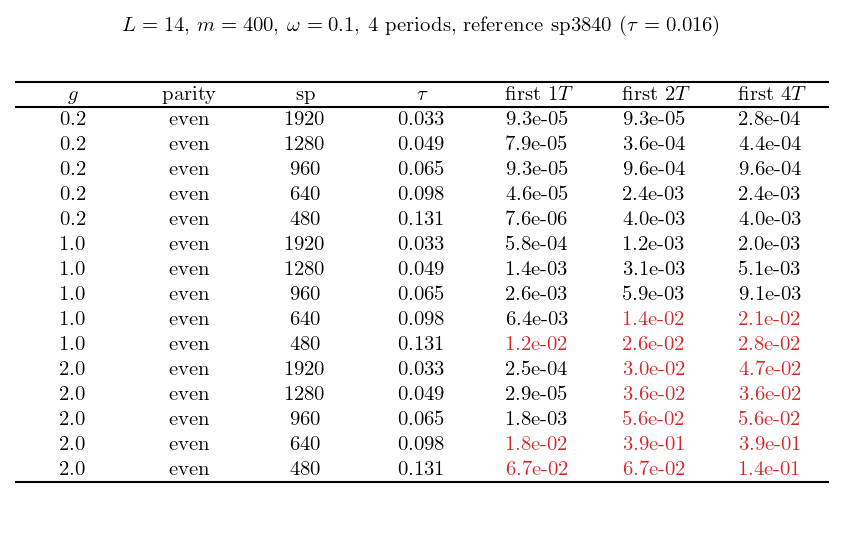

In [30]:
for b in batches:
    rows = []
    for (bb, g, p), rs in sorted(runs.items()):
        if bb != b:
            continue
        Q = excess(rs)
        ref = max(Q)
        ws = [w for w in [1, 2, 4, 10, 20] if w <= len(Q[ref])]
        for sp in sorted(Q, reverse=True)[1:]:
            rel = np.abs(Q[sp] - Q[ref]) / Q[ref]
            rows.append([g, p, sp, f"{rs[sp]['T'] / sp:.3f}", *[f"{rel[:w].max():.1e}" for w in ws]])
    heads = ["$g$", "parity", "sp", r"$\tau$"] + [rf"first {w}$T$" for w in ws]

    fig, ax = plt.subplots(figsize=(7, 0.25 * len(rows) + 0.4), dpi=150)
    ax.axis("off")
    ax.set_title(desc(b), fontsize=10)
    tab = ax.table(cellText=rows, colLabels=heads, loc="center", cellLoc="center")
    for (i, j), cell in tab.get_celld().items():
        cell.visible_edges = "TB" if i == 0 else "B" if i == len(rows) else ""
        if i and j >= 4 and float(cell.get_text().get_text()) > tol:
            cell.get_text().set_color("tab:red")

## Whole run

Same $\varepsilon$ and $p$ over the full run, red is $\varepsilon > 10^{-2}$. At 4 periods $g \le 1$ still roughly follows $\tau^2$ for the finer steps. At 20 periods and $g = 2.0$ it's flat and $p$ is all over the place (even negative). That's the phase drift from above, not a bug.

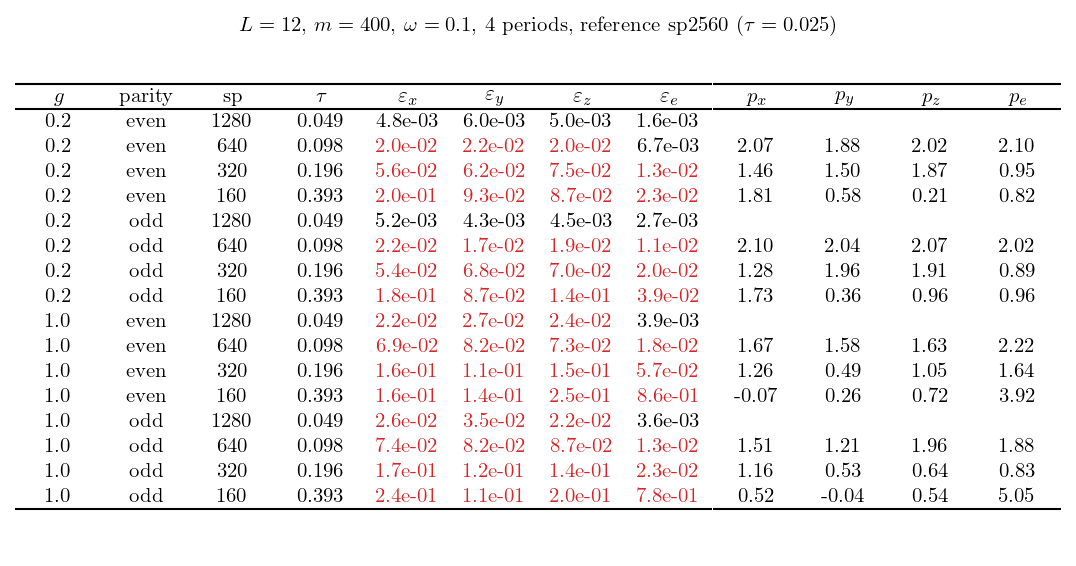

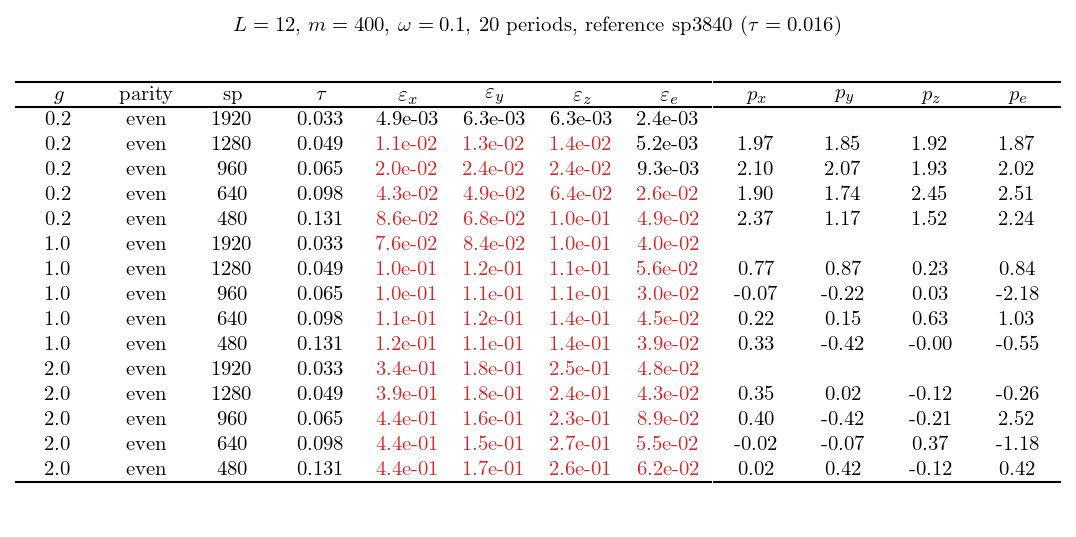

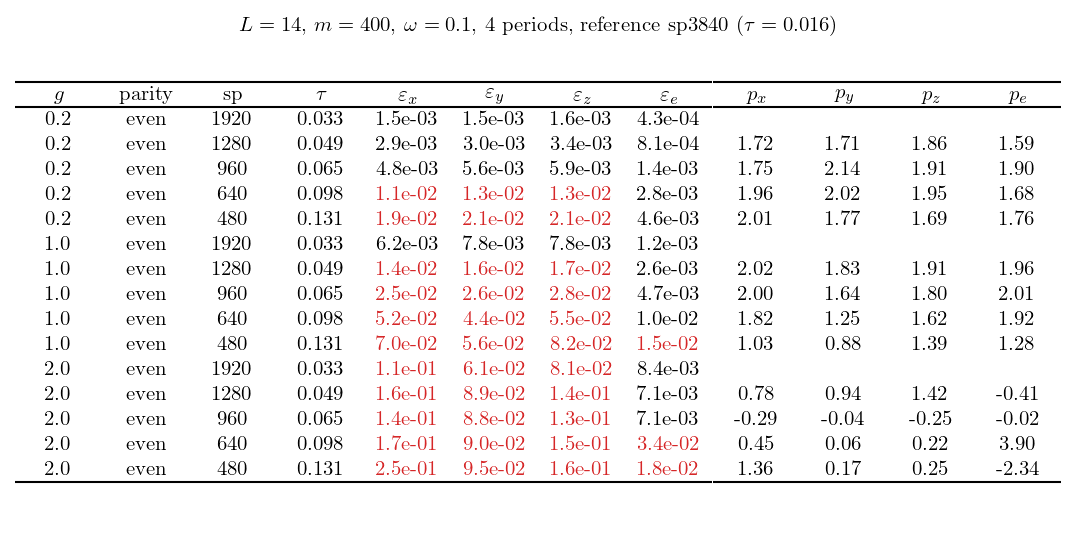

In [31]:
for b in batches:
    rows = [[g, p, sp, f"{r['tau']:.3f}", *[f"{r['eps'][c]:.1e}" for c in chans],
             *[f"{r['order'][c]:.2f}" if "order" in r else "" for c in chans]]
            for (bb, g, p), res in results.items() if bb == b for sp, r in res.items()]
    heads = ["$g$", "parity", "sp", r"$\tau$"] + [rf"$\varepsilon_{c}$" for c in chans] + [f"$p_{c}$" for c in chans]

    fig, ax = plt.subplots(figsize=(9, 0.25 * len(rows) + 0.4), dpi=150)
    ax.axis("off")
    ax.set_title(desc(b), fontsize=10)
    tab = ax.table(cellText=rows, colLabels=heads, loc="center", cellLoc="center")
    for (i, j), cell in tab.get_celld().items():
        cell.visible_edges = "TB" if i == 0 else "B" if i == len(rows) else ""
        if i and 4 <= j < 8 and float(cell.get_text().get_text()) > tol:
            cell.get_text().set_color("tab:red")

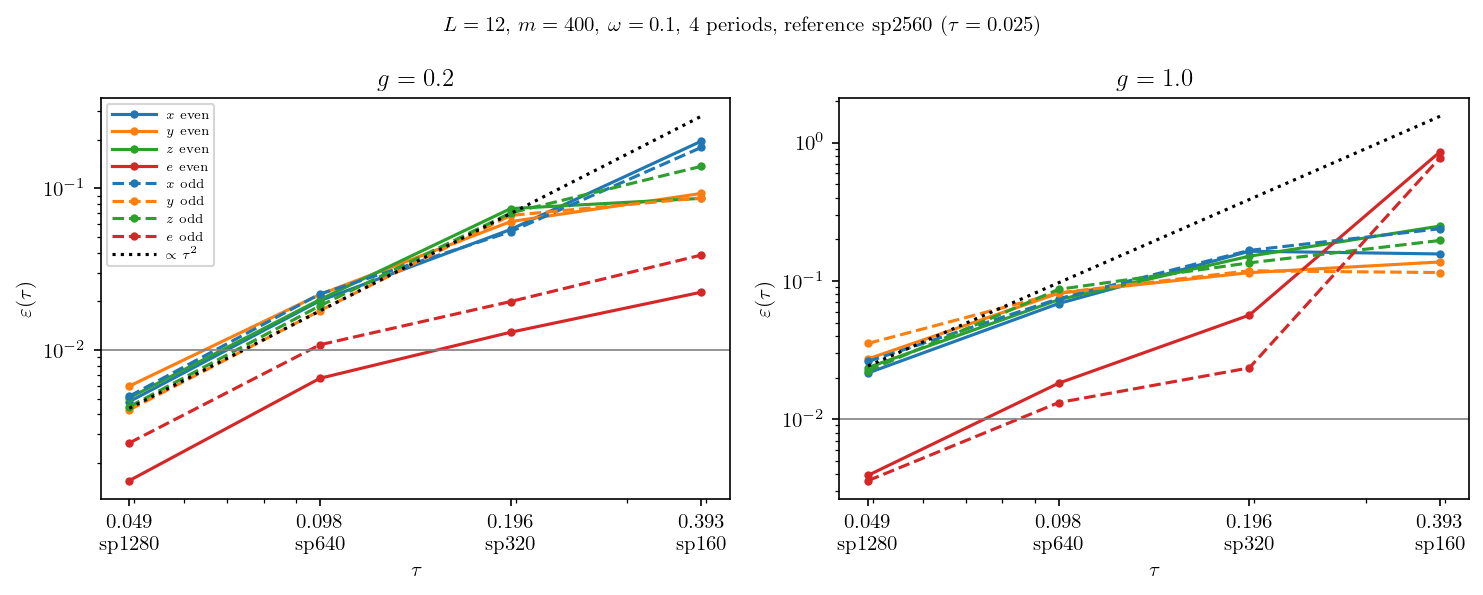

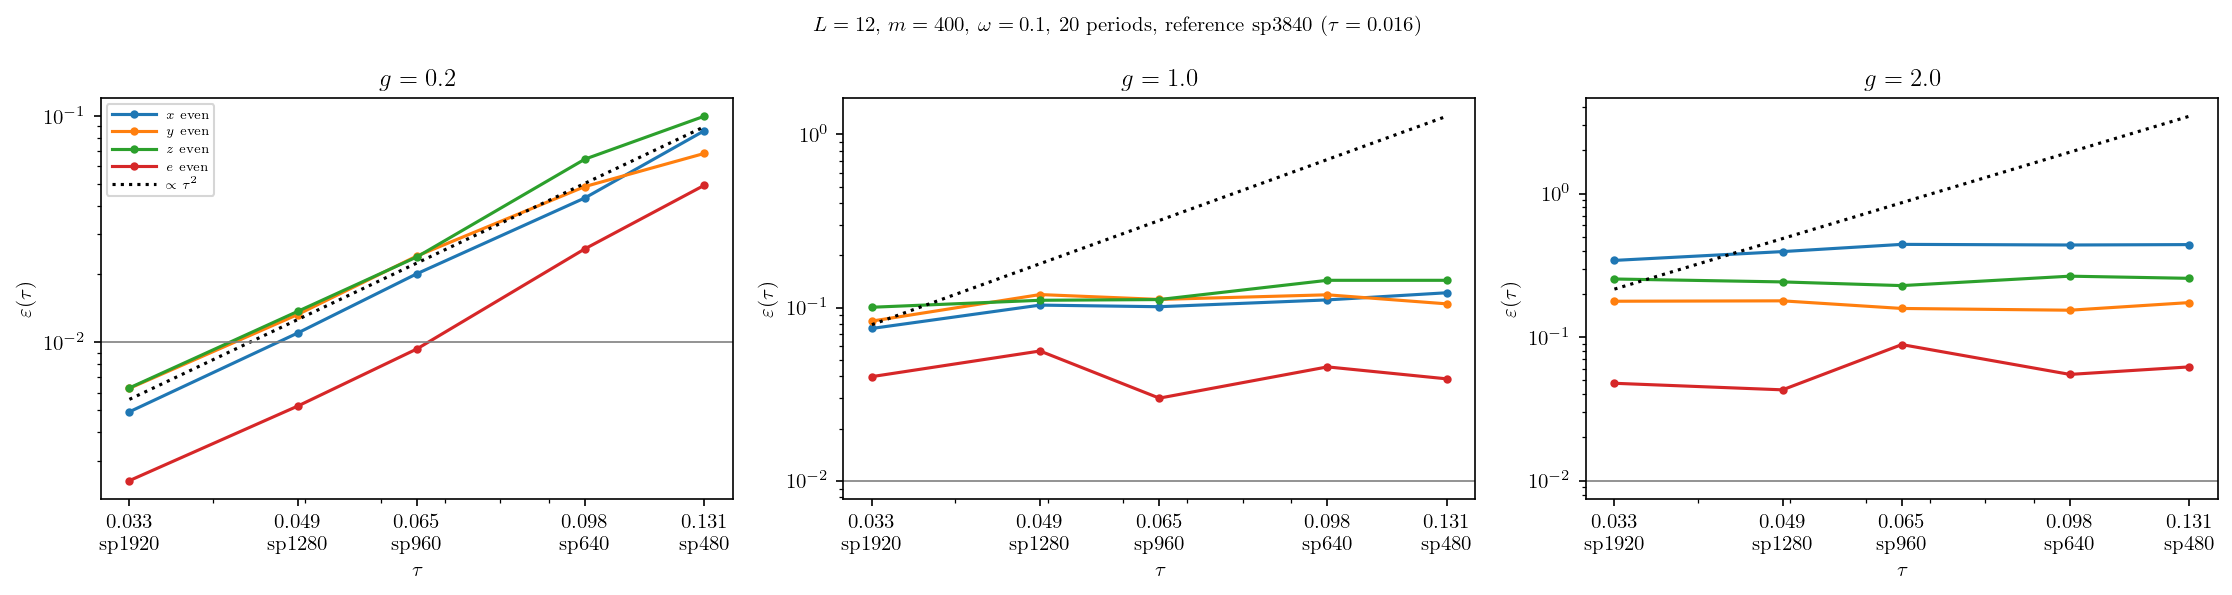

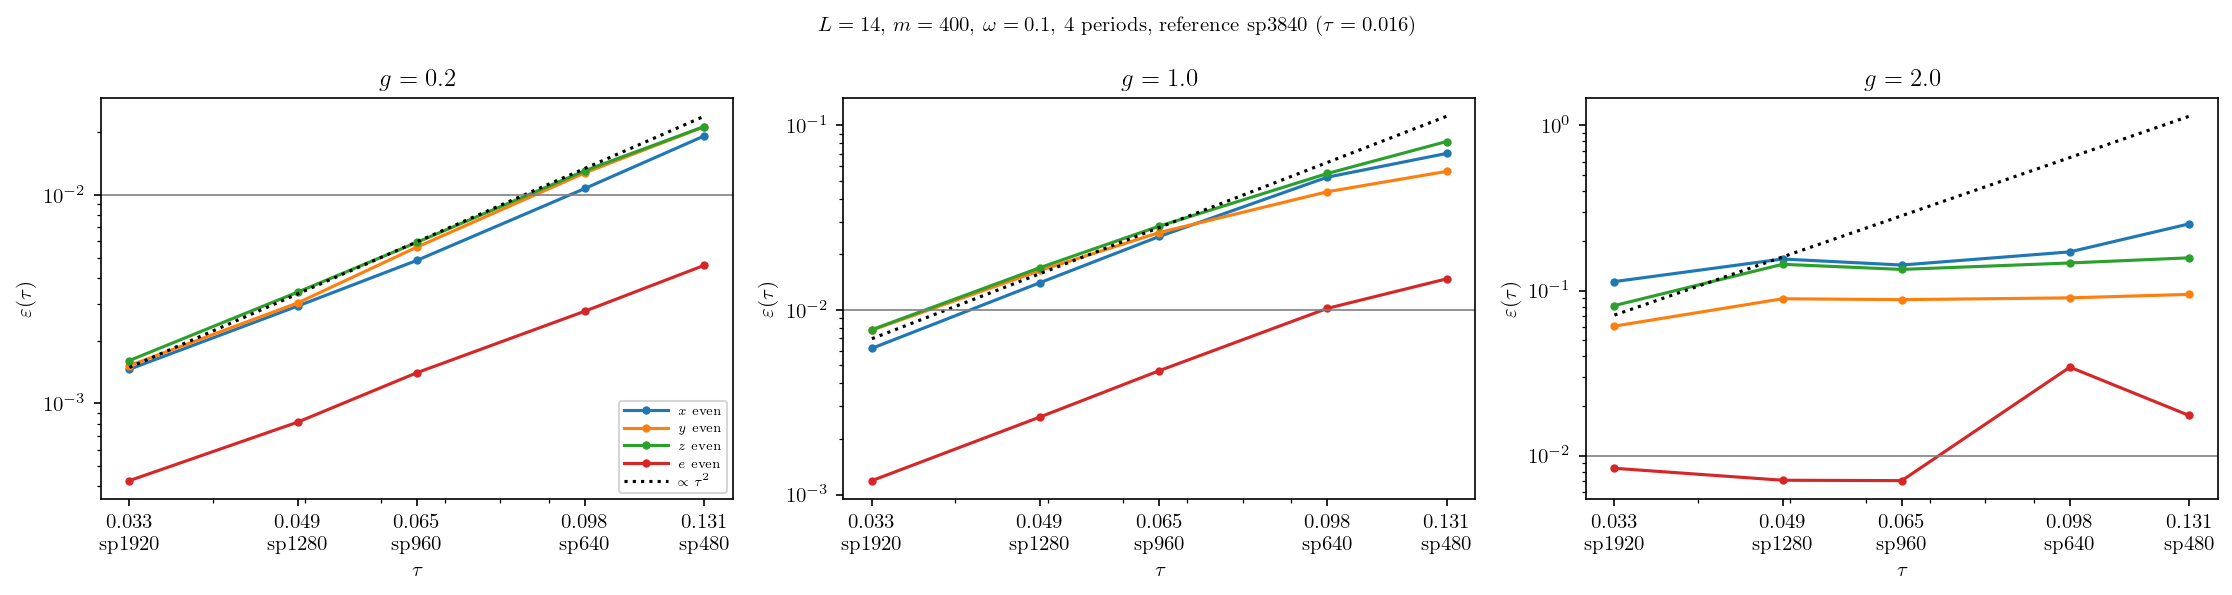

In [32]:
for b in batches:
    plot_eps(results, b)

## Raw data

Real parts of the autocorrelations and $\langle H(t)\rangle/L$ for every $\tau$.

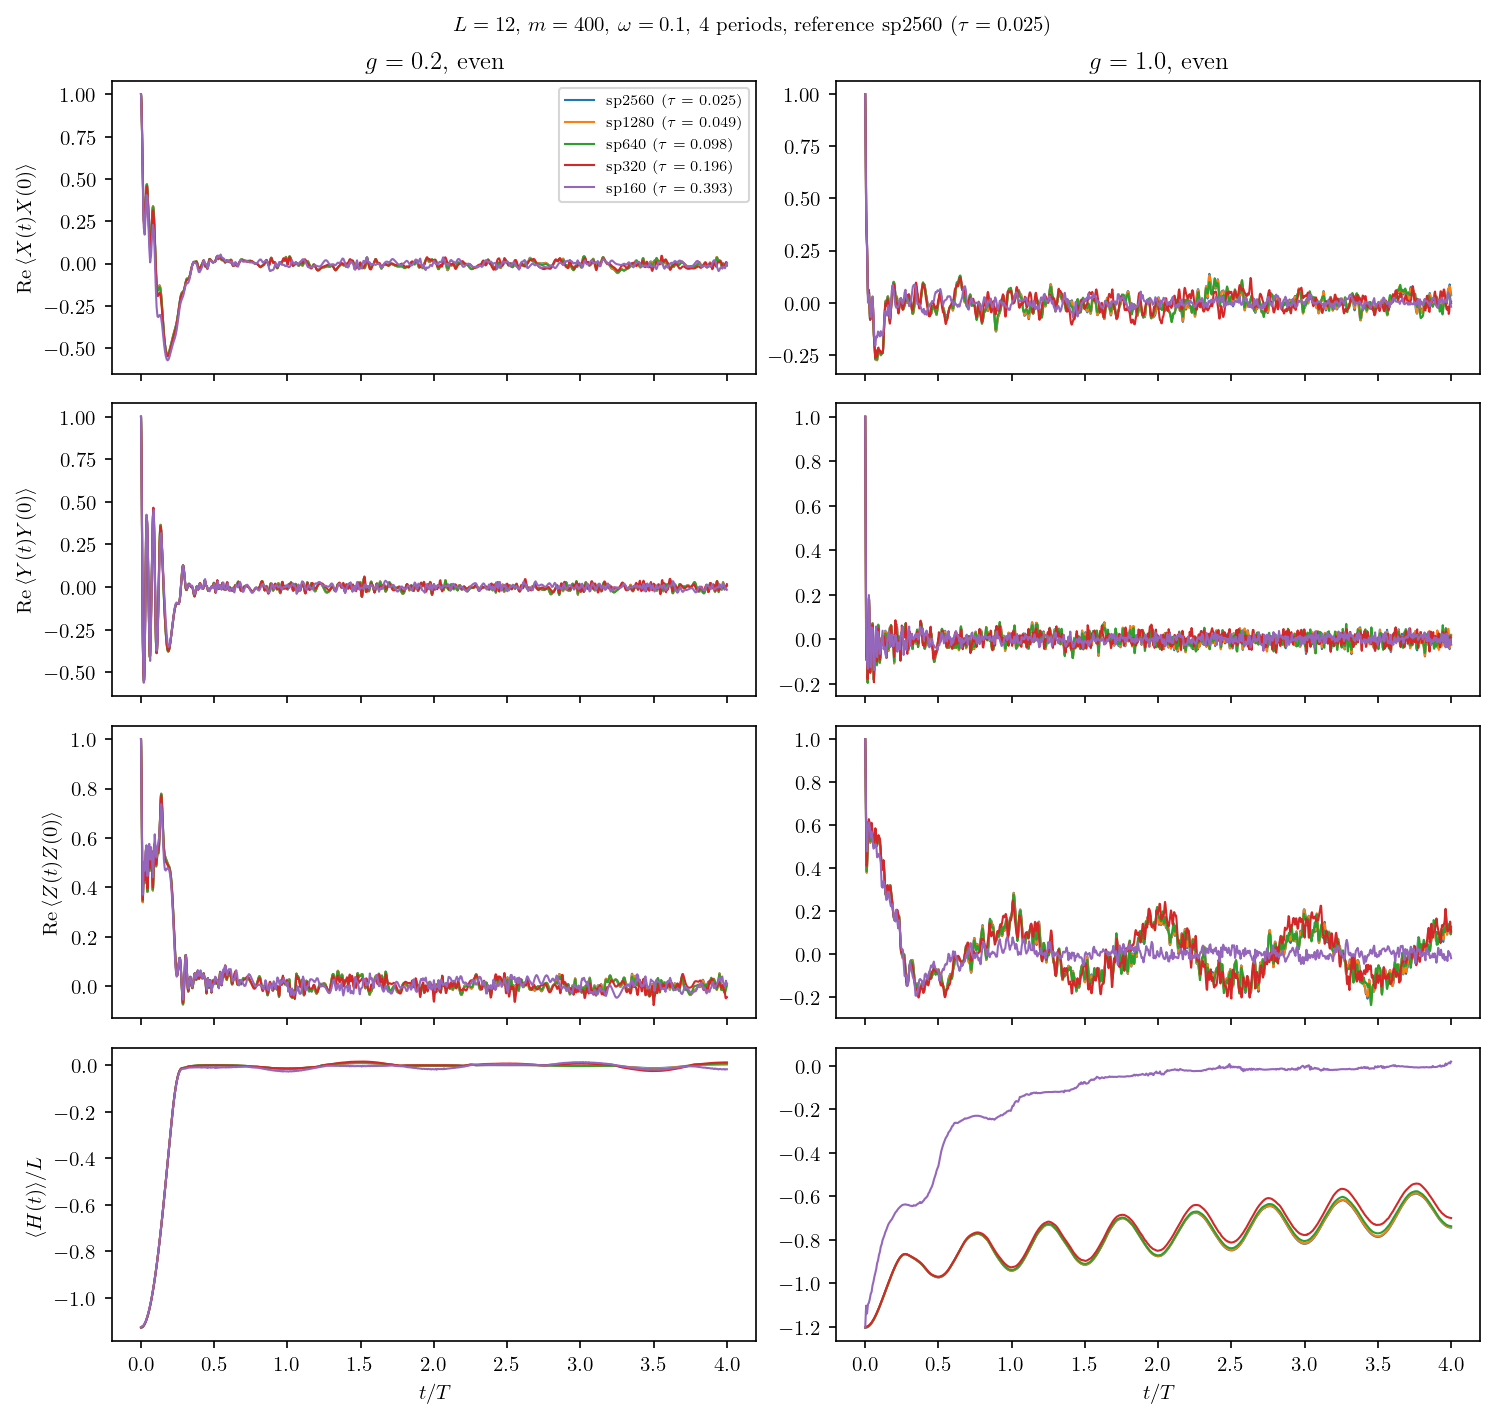

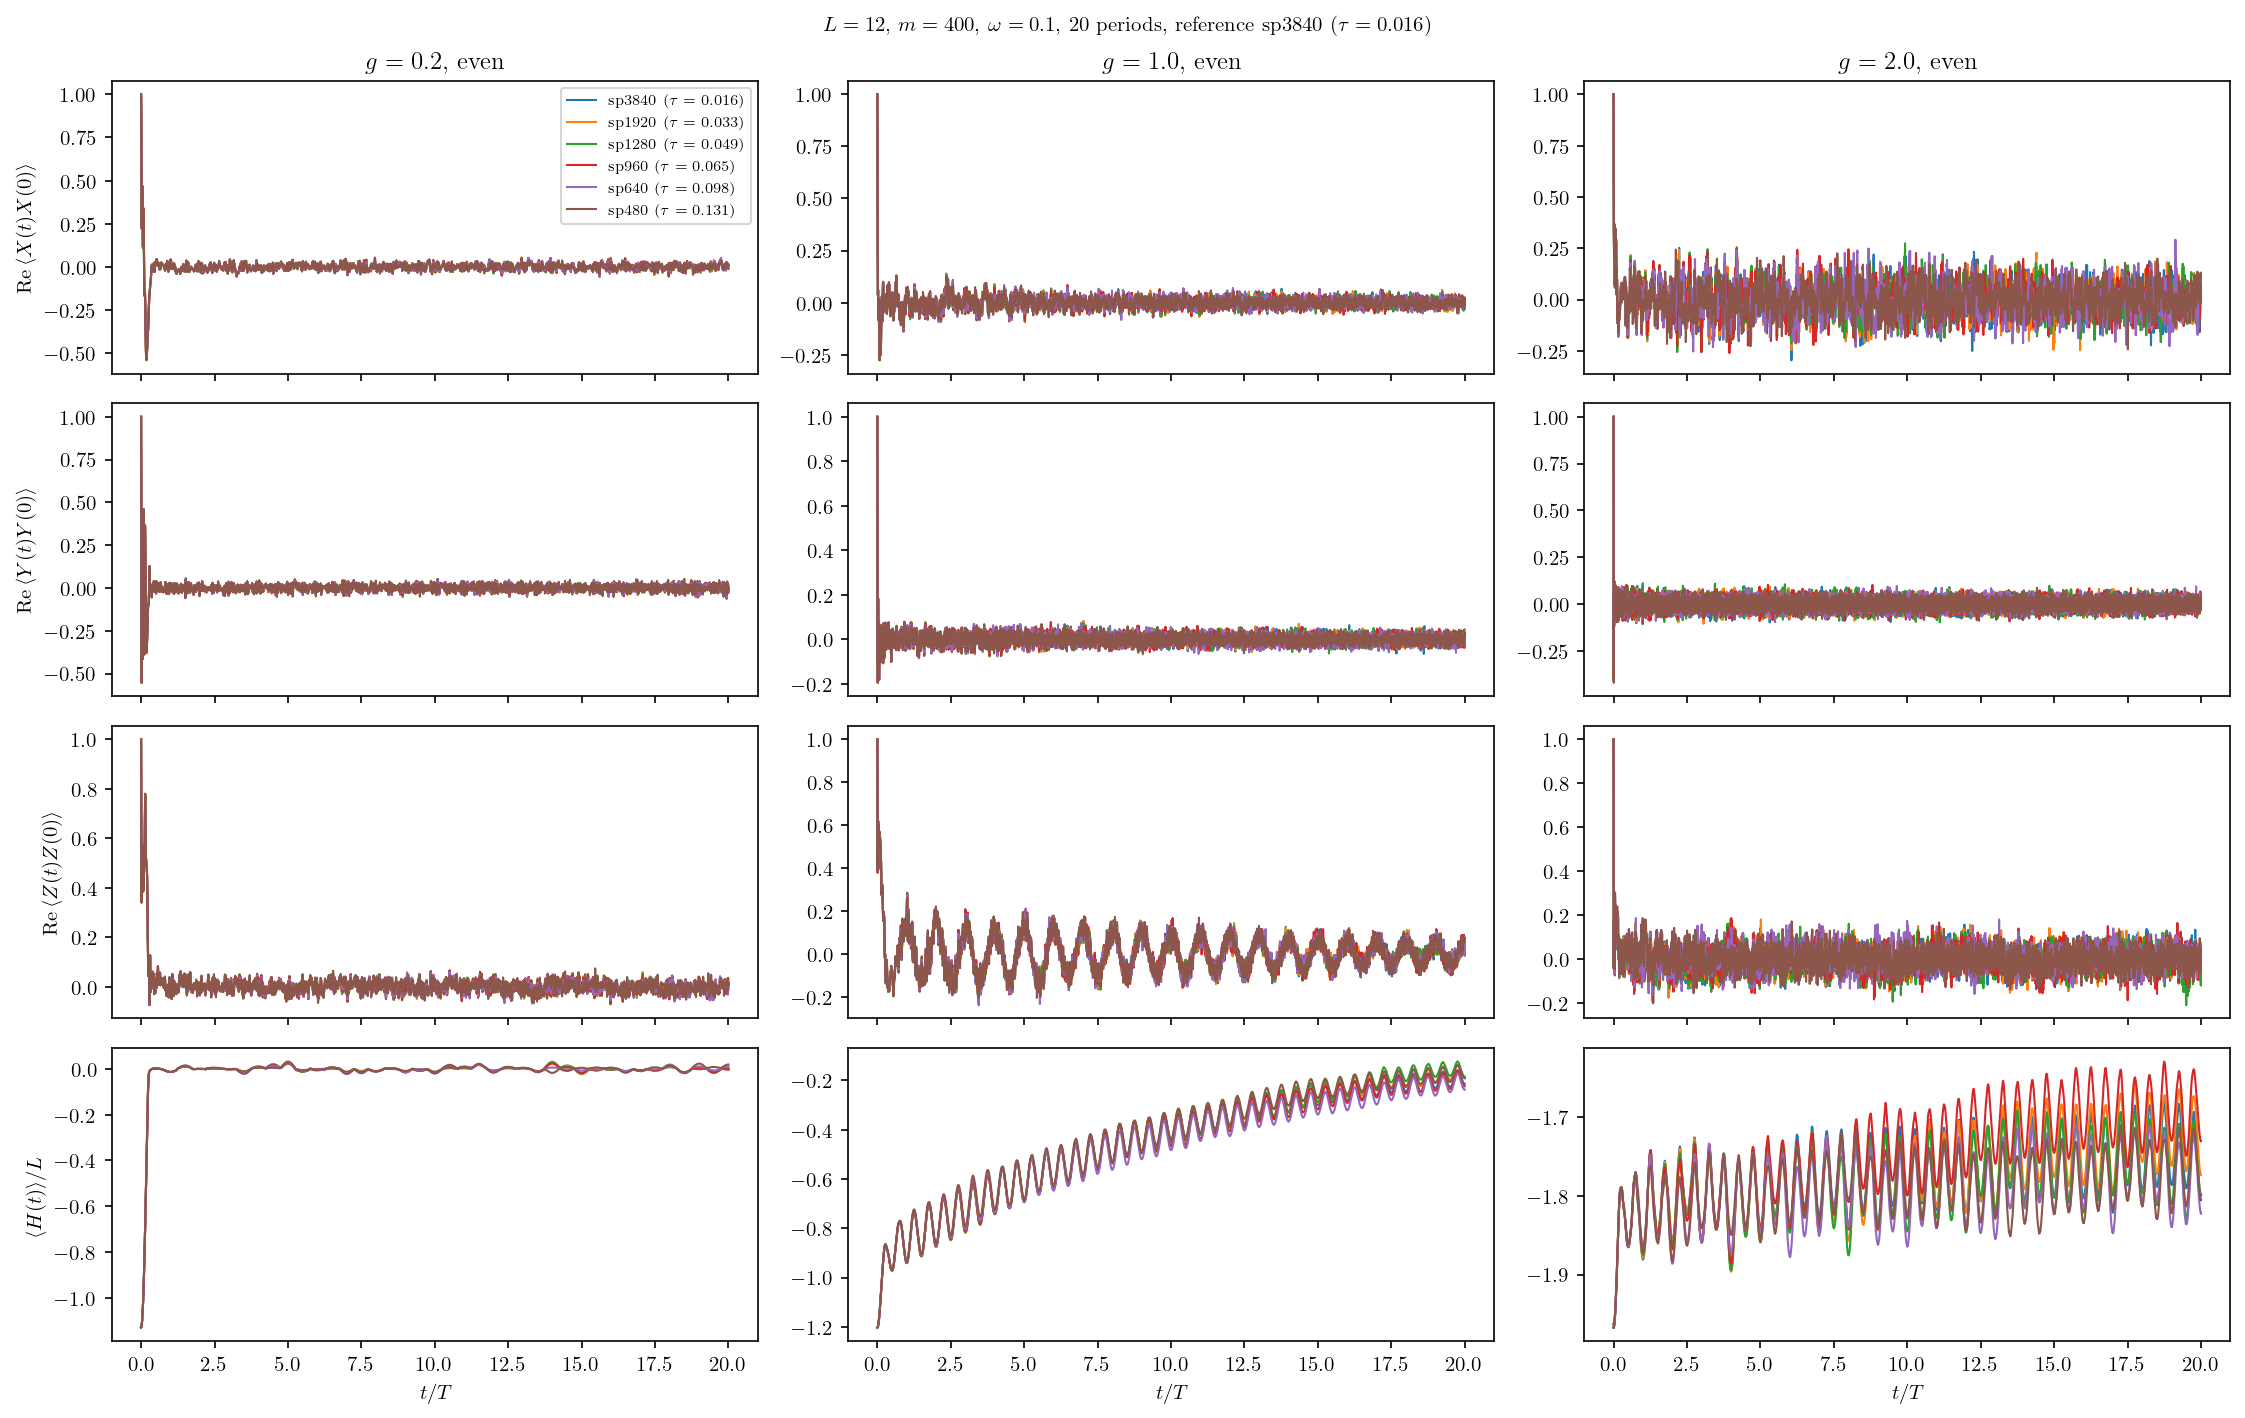

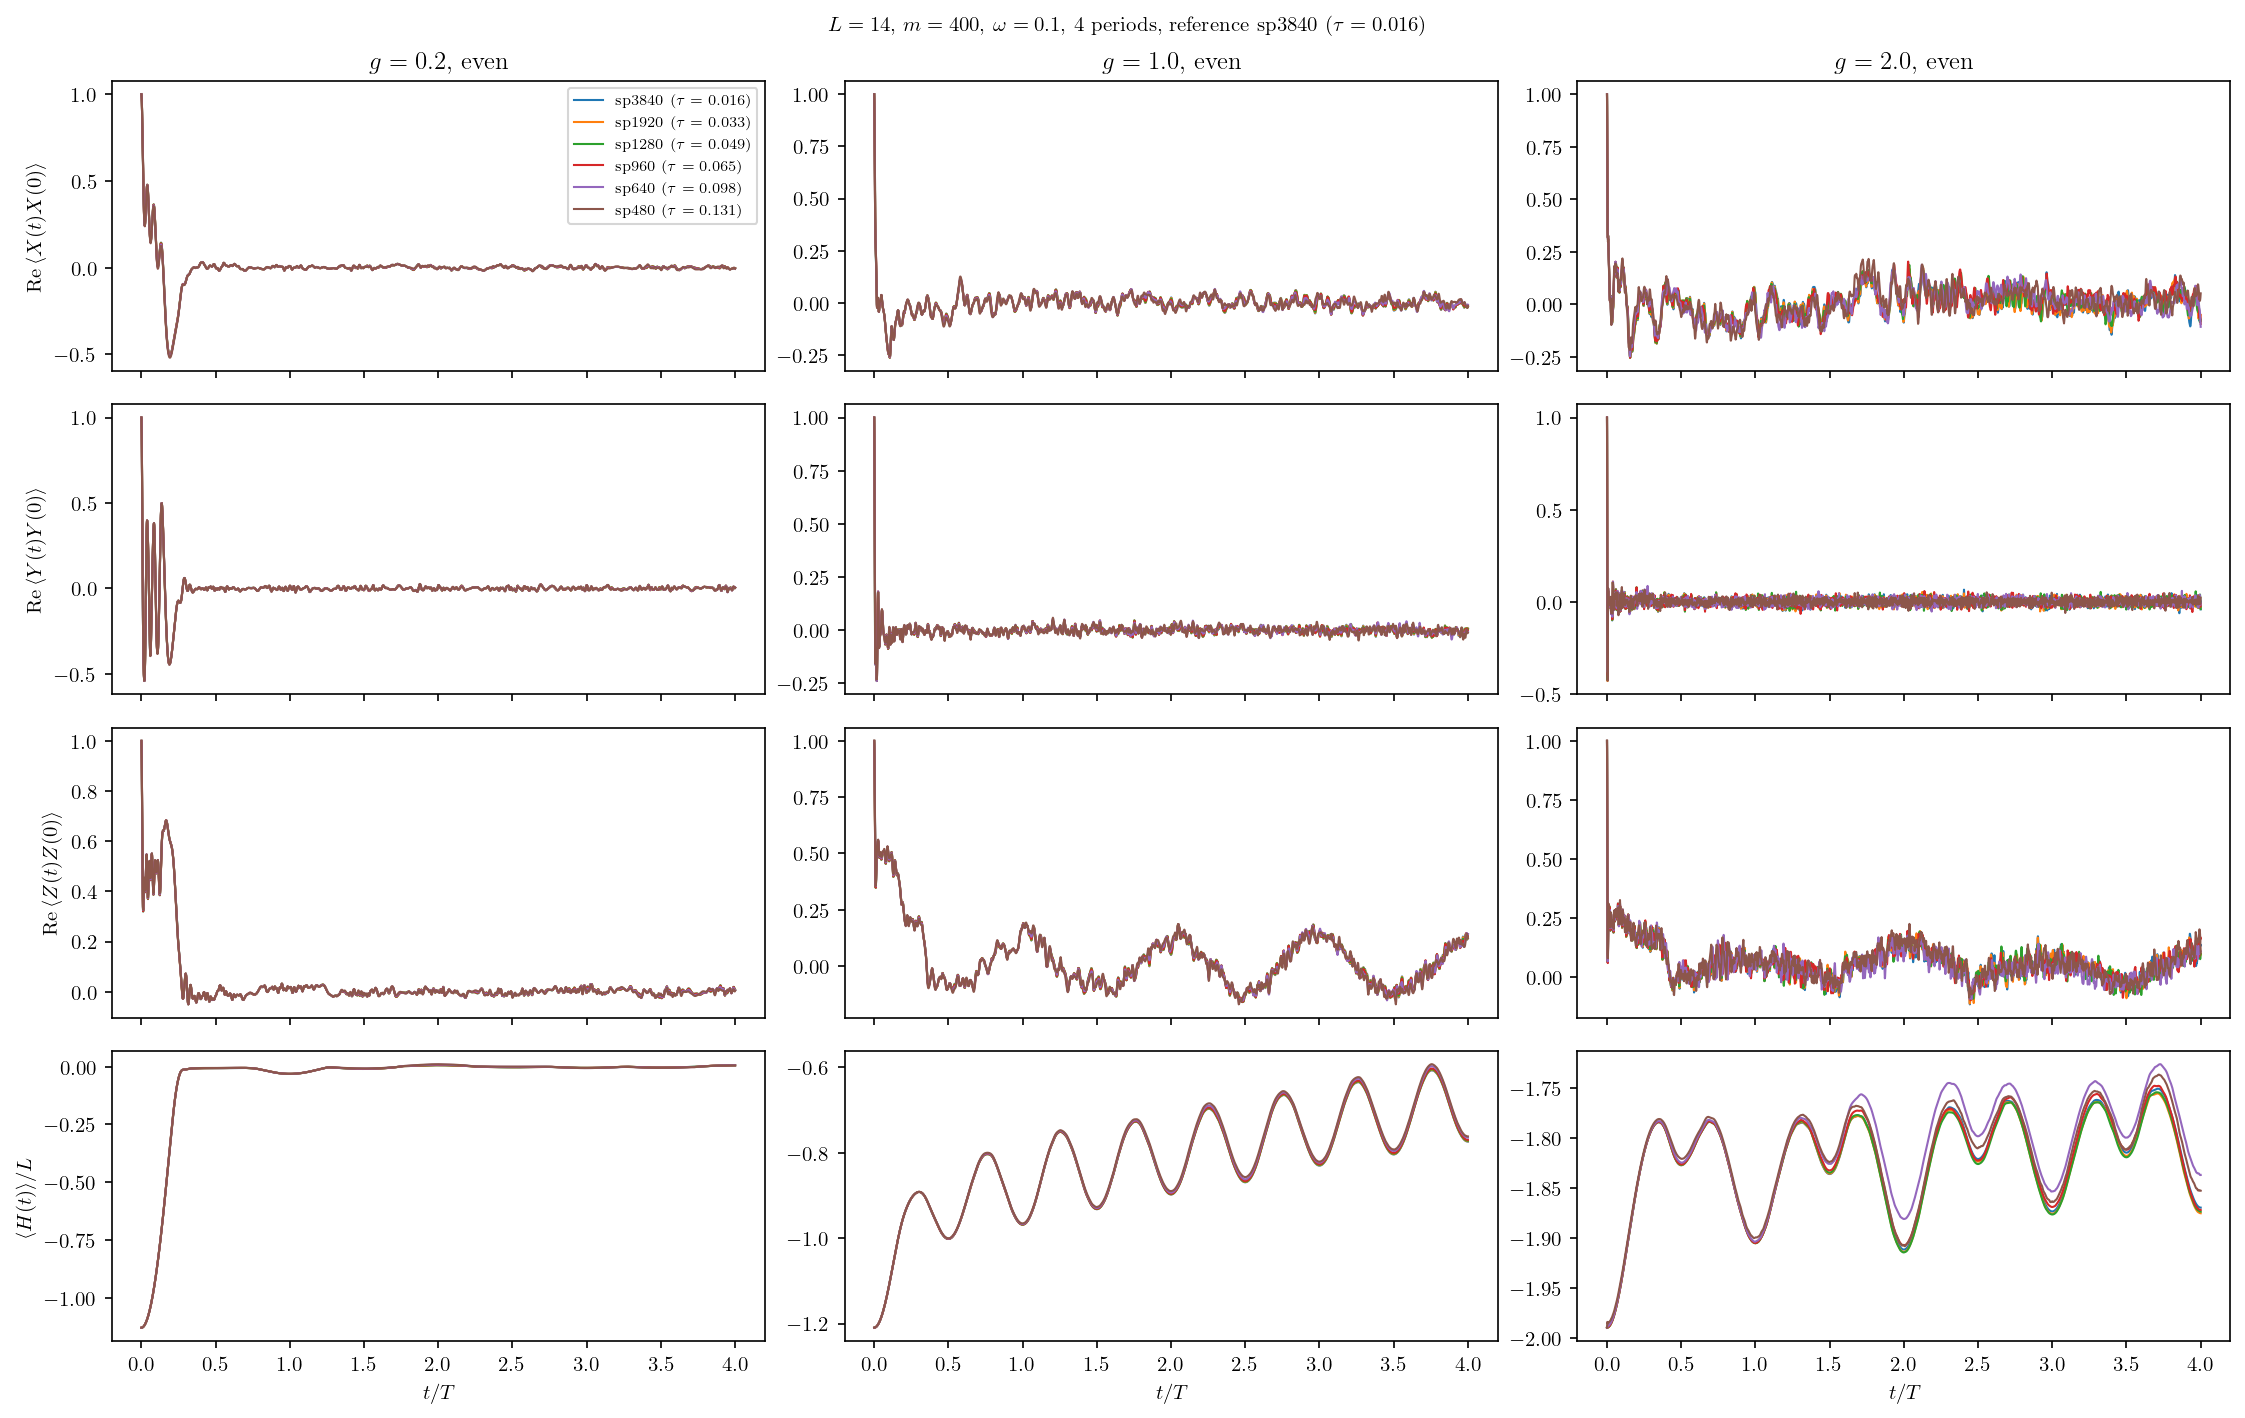

In [33]:
for b in batches:
    fig, ax = plt.subplots(len(chans), len(gs(b)), figsize=(5 * len(gs(b)), 2.4 * len(chans)), sharex=True, squeeze=False, dpi=150)
    for j, g in enumerate(gs(b)):
        rs = runs[(b, g, par(b, g))]
        for sp in sorted(rs, reverse=True):
            d = rs[sp]
            for i, c in enumerate(chans):
                ax[i, j].plot(d["t"] / d["T"], d[c].real, lw=1, label=rf"sp{sp} ($\tau = {d['T'] / sp:.3f}$)")
        ax[0, j].set_title(rf"$g = {g}$, {par(b, g)}")
        ax[-1, j].set_xlabel(r"$t/T$")
    for i, c in enumerate(chans):
        ax[i, 0].set_ylabel(chans[c] if c == "e" else r"$\mathrm{Re}\,$" + chans[c])
    ax[0, 0].legend(fontsize=7)
    fig.suptitle(desc(b), fontsize=10)
    fig.tight_layout()

Running max error vs the reference (worst of $x$, $y$, $z$ and energy). Grows, then flattens out around the size of the signal.

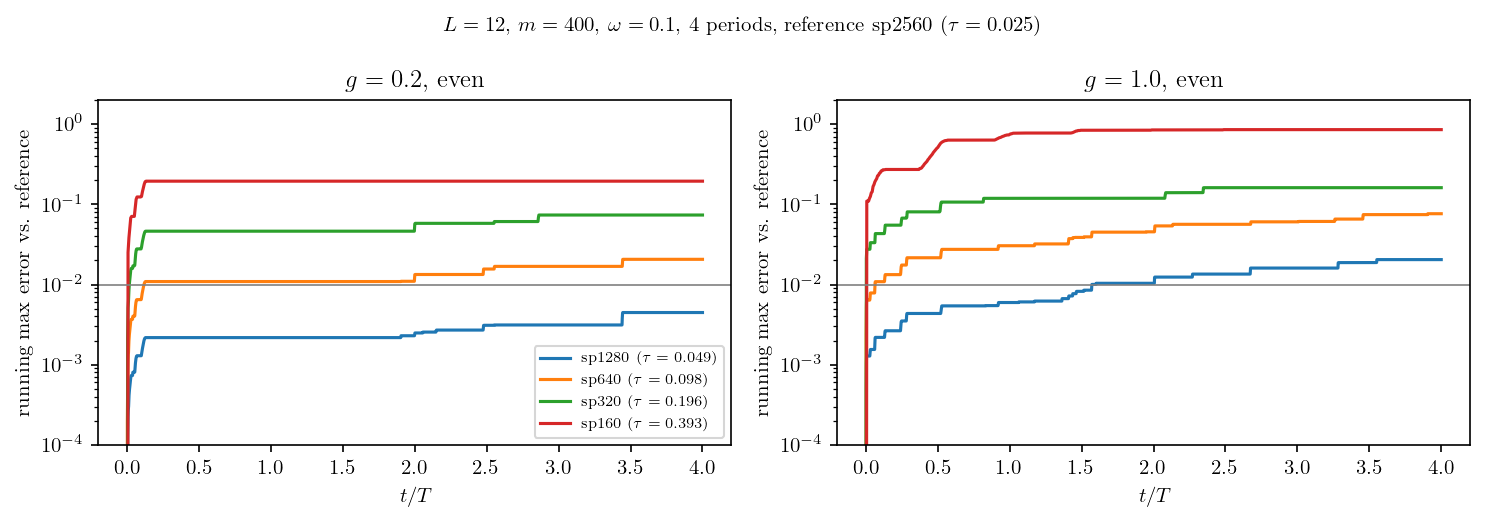

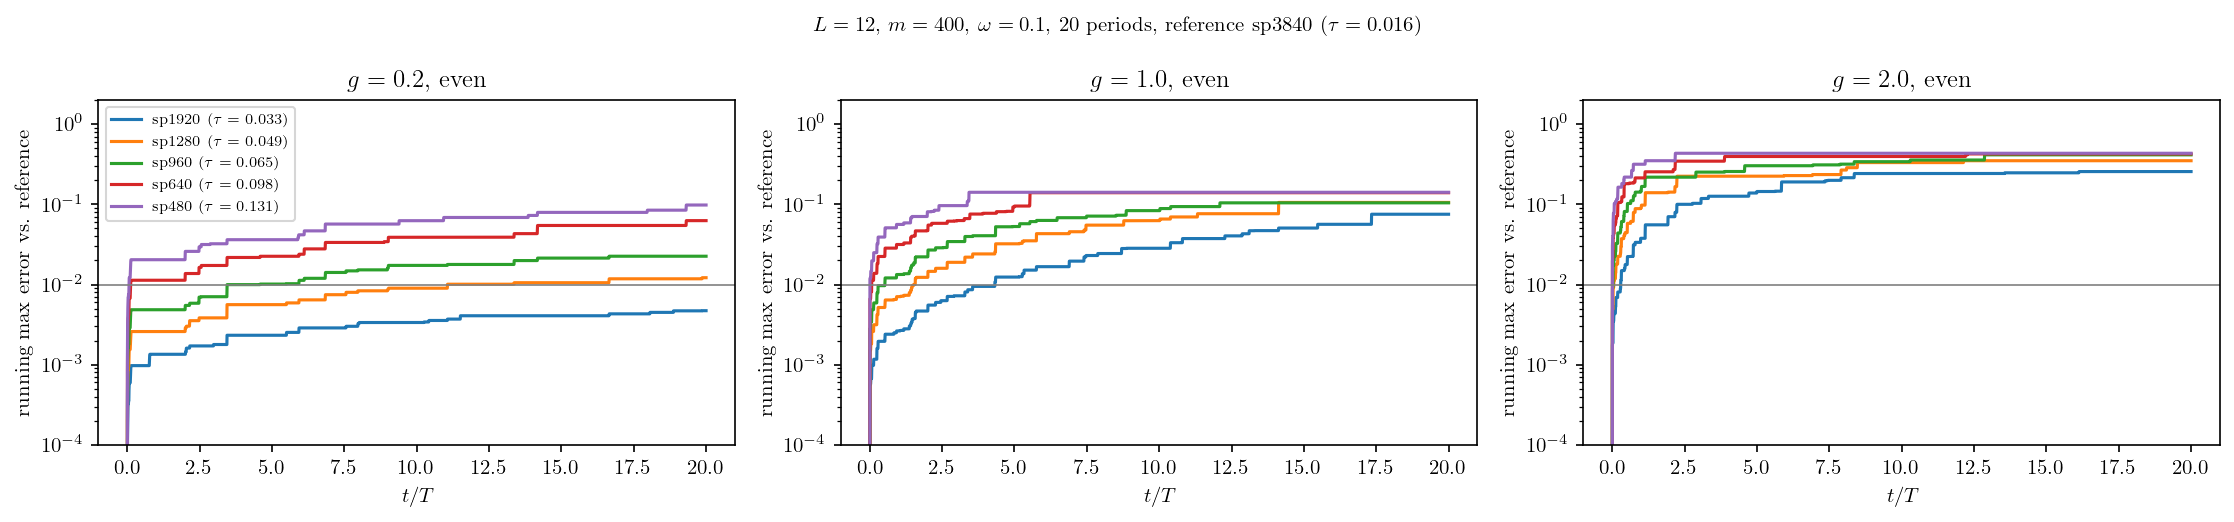

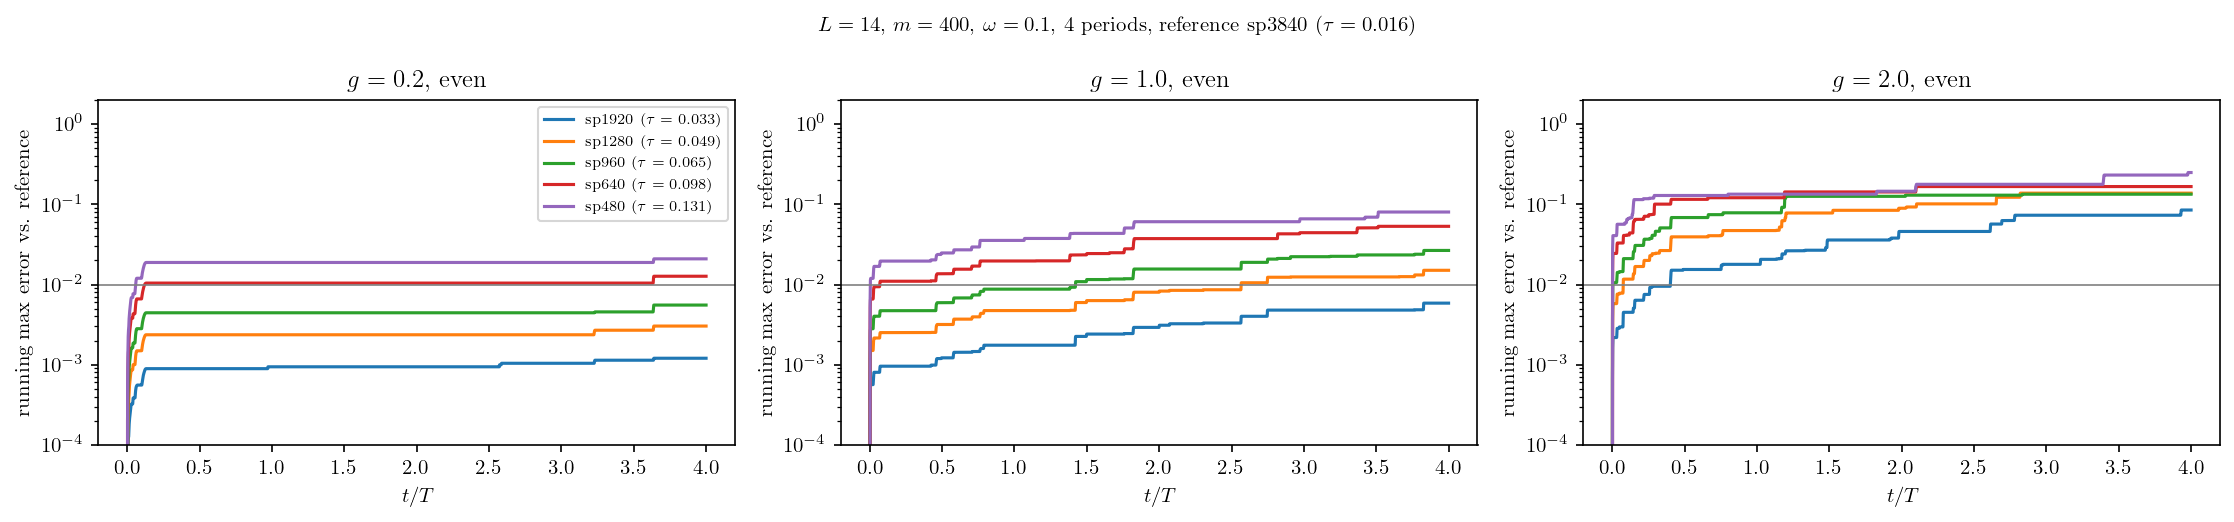

In [34]:
for b in batches:
    fig, ax = plt.subplots(1, len(gs(b)), figsize=(5 * len(gs(b)), 3.5), squeeze=False, dpi=150)
    for j, g in enumerate(gs(b)):
        k = (b, g, par(b, g))
        T = runs[k][max(runs[k])]["T"]
        for sp, r in results[k].items():
            ax[0, j].semilogy(r["t"] / T, np.max([r["run_err"][c] for c in chans], axis=0), label=rf"sp{sp} ($\tau = {r['tau']:.3f}$)")
        ax[0, j].axhline(tol, color="gray", lw=0.8)
        ax[0, j].set(title=rf"$g = {g}$, {par(b, g)}", xlabel=r"$t/T$", ylabel="running max error vs. reference", ylim=(1e-4, 2))
    ax[0, 0].legend(fontsize=7)
    fig.suptitle(desc(b), fontsize=10)
    fig.tight_layout()

## Late-time autocorrelations

Colored lines are the rms error vs the reference, dashed is the rms of the reference itself. Both are averaged over $x$, $y$, $z$ and over each period. Once a colored line hits the dashed one the error is as big as the signal, so I wouldn't trust anything past that.

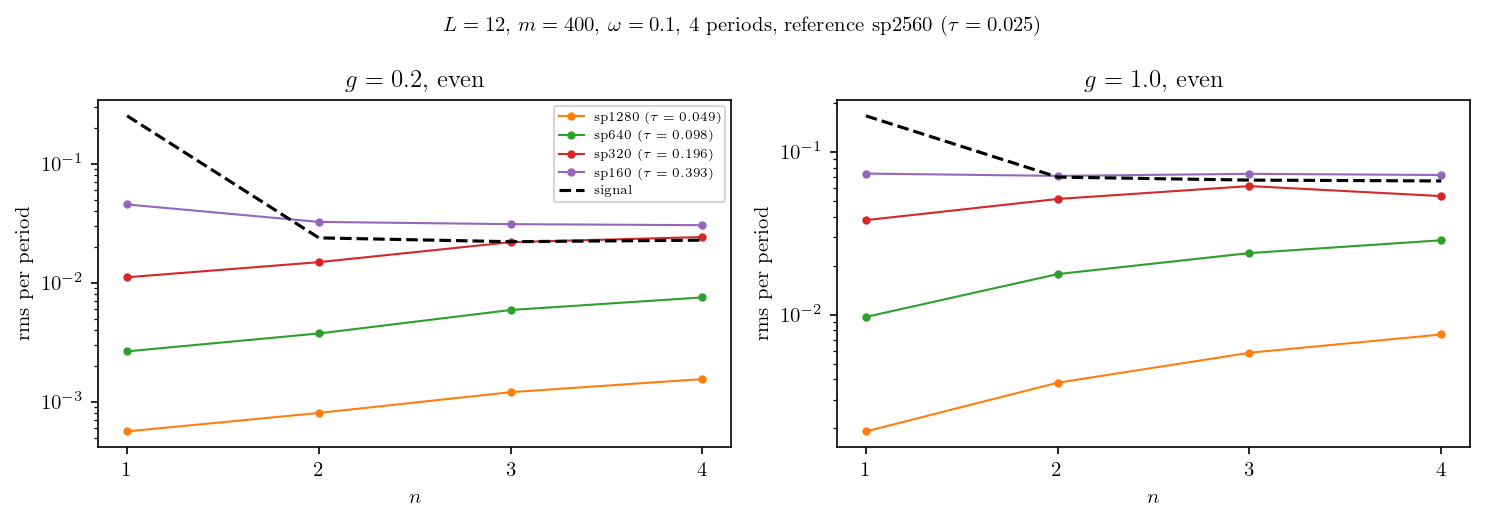

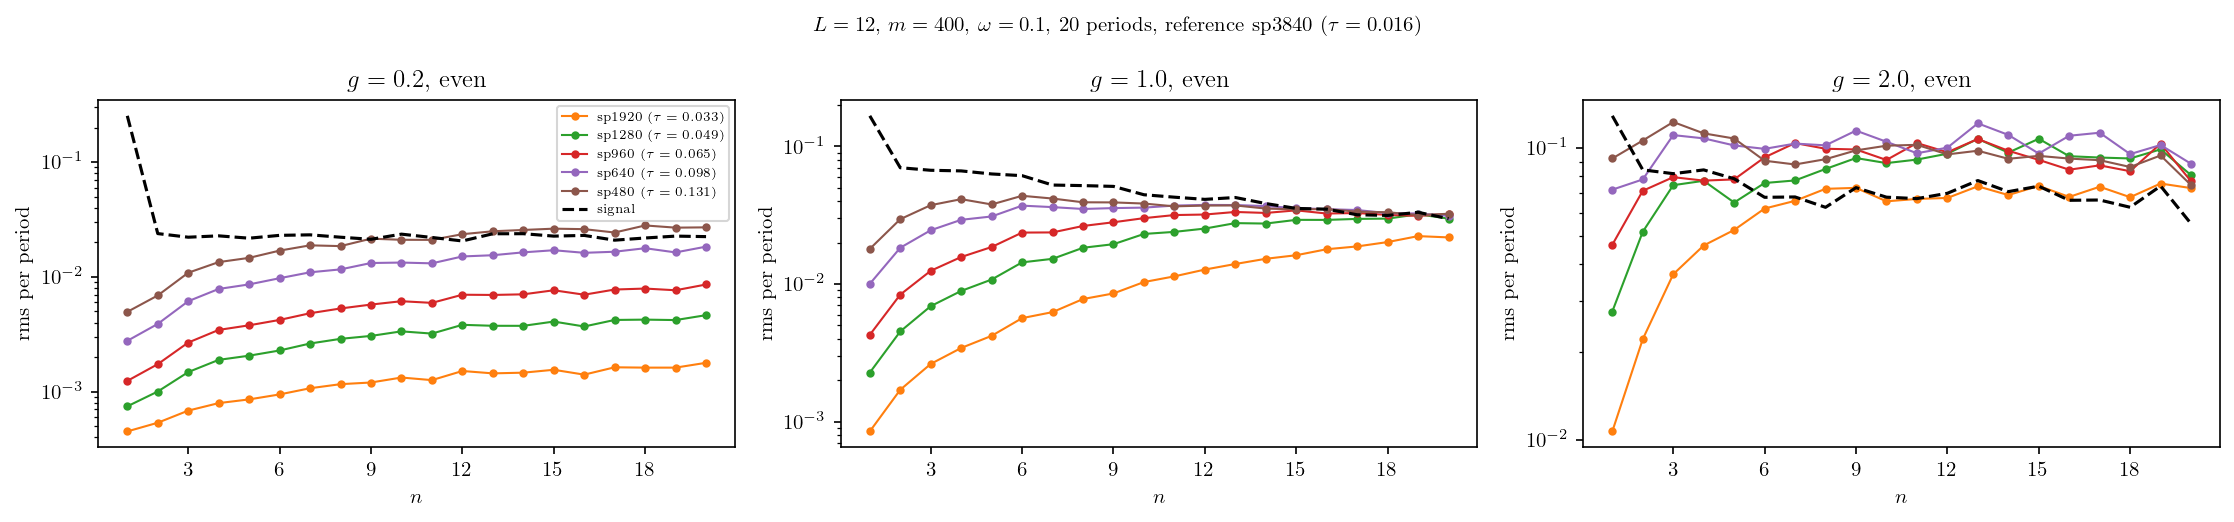

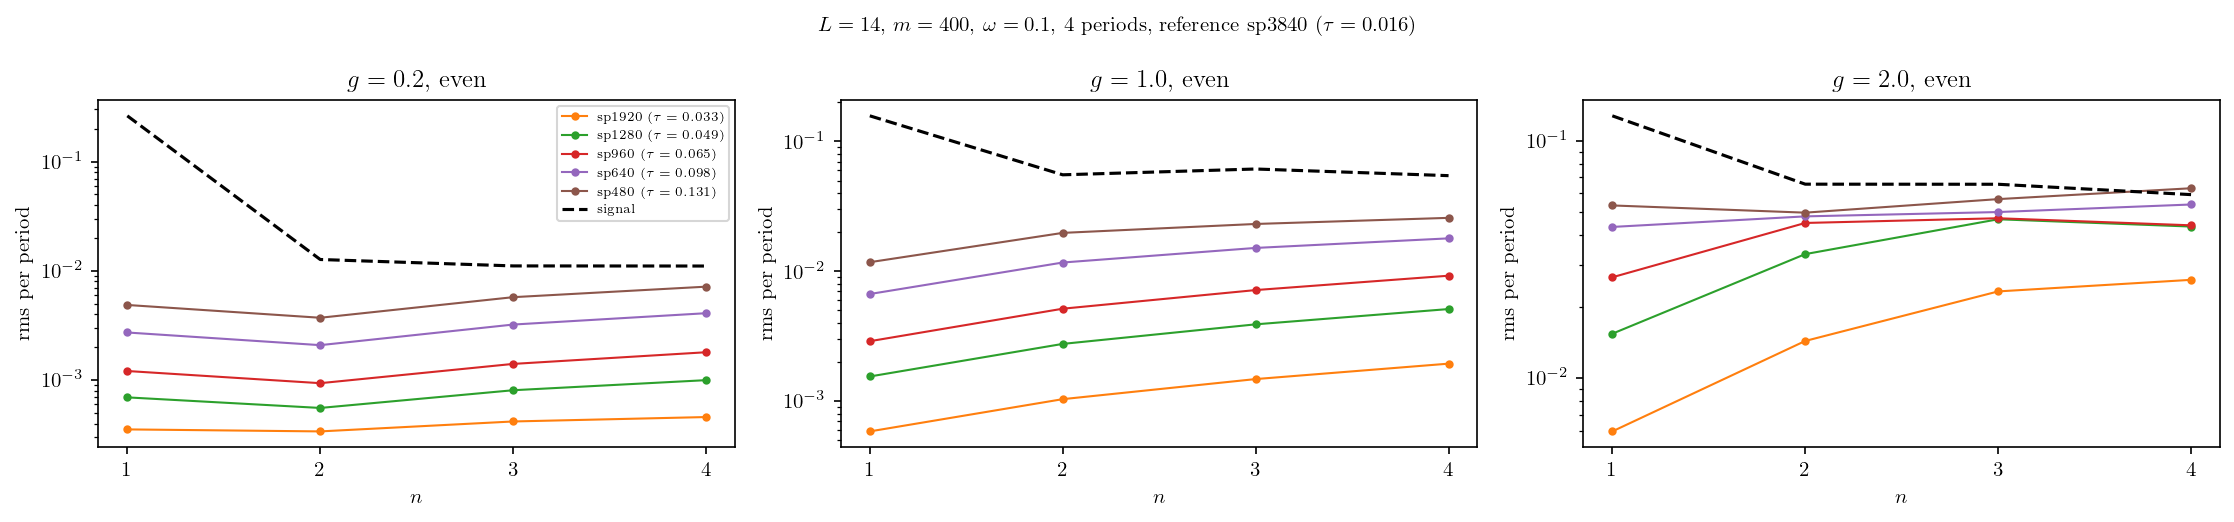

In [35]:
for b in batches:
    fig, ax = plt.subplots(1, len(gs(b)), figsize=(5 * len(gs(b)), 3.5), squeeze=False, dpi=150)
    for j, g in enumerate(gs(b)):
        rs = runs[(b, g, par(b, g))]
        ref = max(rs)
        n = round(rs[ref]["t"][-1] / rs[ref]["T"])
        A = {sp: np.stack([d[c] for c in "xyz"]) for sp, d in rs.items()}
        k = np.arange(1, n + 1)
        for i, sp in enumerate(sorted(rs, reverse=True)[1:], 1):
            ax[0, j].semilogy(k, period_rms(A[sp] - A[ref][:, :: ref // sp], n), marker="o", ms=3, lw=1, color=f"C{i}",
                              label=rf"sp{sp} ($\tau = {rs[sp]['T'] / sp:.3f}$)")
        ax[0, j].semilogy(k, period_rms(A[ref], n), "k--", lw=1.5, label="signal")
        ax[0, j].set(title=rf"$g = {g}$, {par(b, g)}", xlabel=r"$n$", ylabel="rms per period")
        ax[0, j].xaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0, 0].legend(fontsize=6, loc="upper right")
    fig.suptitle(desc(b), fontsize=10)
    fig.tight_layout()